# The noise estimator of the matched-filter search

The blind search turns a light curve into an SNR trace in four steps: a rolling-median **baseline**, the
**residual** `signal / baseline - 1`, the **matched-filter output** (the residual correlated with the
template), and a division by a **local noise level** of that output, `amp_sigma`
(`normalization="empirical"`, `matched_filter.empirical_filter_sigma`). This notebook looks at the last
step.

It started from a cadence comparison: searching the native 0.524 ms records instead of the 5.24 ms
bins (10 records) gives the same SNR *on average* (1.00 ± 0.02 over the 2026-08-19 runs), but
individual events moved by ±10–15 % between the two cadences. The cause is not the cadence. The noise
estimator is itself noisy: it measures the scatter in 2 s blocks of a filter output that is correlated
over ~2 s, so it rests on about one independent value per block and about ten per window, and moving
the block edges is enough to change it by tens of percent.

**Contents**
0. Data: night 2026-08-19, four stars × three telescopes, good-time windows, native and 5.24 ms
1. From light curve to SNR, step by step (HD170263, MAGIC-2)
2. Native vs 5.24 ms on all channel-runs
3. The same estimator on a changed sampling grid, and block-edge shifts
4. What it does to the SNR and the false-alarm rate (single telescope and 2-of-3)
5. Candidate fixes: one block per window, a sliding (overlapping) robust scatter, longer windows
6. Appendix: sub-bin-shifted templates

**In short** (details in the Conclusions at the end):
* The cadence makes no difference. The pipeline's σ estimate is noisy: ±40 % (rms of log) on
  stationary noise, and 7 % low on average.
* At equal false-alarm rate this costs a lot of efficiency on stationary noise (0.49 vs 0.84 with a
  perfect σ). On real data the noise level also really changes, so long windows are worse, not better.
* A sliding (overlapping) 16 s window is at least as good as the current estimator in every test here,
  and better in most.
* Separately, the rolling-median baseline makes the SNR tails non-Gaussian even with a perfect σ.
* Sub-bin-shifted templates gain 0.4–1 % (up to 3 % at the worst phase) at no measurable FAR cost.

Everything uses the package's own search code (`compute_baseline_and_sigma`,
`sliding_matched_filter_snr`, `empirical_filter_sigma`, `find_candidates`, the mimic/coincidence helpers).
The fixes exist only here, as functions that return an `amp_sigma`, which is passed back through
`sliding_matched_filter_snr`'s output. The package is unchanged.

In [1]:
import time as _time
import warnings
from dataclasses import replace
from functools import partial
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.special import ndtr
from scipy.stats import kurtosis
from scipy.signal import welch
from IPython.display import display

from kbo_occultation import load_observation_log
from kbo_occultation.config import ORM_ARRAY
from kbo_occultation.observations.photometry import LightCurve
from kbo_occultation.analysis.mimic import (MimicConfig, star_bank, search_templates, bank_instrument, bin_lightcurve,
                                            _template_duration, _telescope_results, _event_rows)
from kbo_occultation.analysis.matched_filter import (compute_baseline_and_sigma, sliding_matched_filter_snr,
                                                     empirical_filter_sigma, find_candidates)
from kbo_occultation.analysis.coincidence import coincidence_tolerance_s, accidental_coincidence_rate
from kbo_occultation.analysis.surrogates import phase_randomized_lightcurve
from kbo_occultation.analysis.noise_removal import star_fraction_for, threshold_for_far
from kbo_occultation.simulation.kinematics import (EARTH_SEMIMAJOR_AXIS_AU, ShadowKinematics,
                                                   shadow_velocity_opposition)

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 40)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()      # repository root
OUT = ROOT / "outputs" / "notebooks" / "sigma_estimator"
OUT.mkdir(parents=True, exist_ok=True)

# ── how much to compute ──────────────────────────────────────────────────────────────────────────────
QUICK = False                    # True: a few minutes; False: more surrogates and injections (~20 min)
SEED = 0
N_SURR = 10 if QUICK else 40     # Gaussian surrogates per channel-run (sections 4-6)
N_INJ = 60 if QUICK else 200     # injections per channel-run and estimator (sections 4-5)
N_SHIFTS = 200                   # time slides for the accidental 2-of-3 background

NIGHT = "2026-08-19"
FOCUS = ("HD170263", "A")        # the longest good-time window (347 s), MAGIC-2
RADIUS = 100.0                   # template used for the single-template diagnostics [m]
SNR_FLOOR = 3.0                  # candidate floor, as MimicConfig.snr_threshold
FAR_SINGLE = 10.0                # per telescope-hour: measurable on ~0.5 telescope-hours of real data
FAR_COINC = 1.0                  # per hour, 2-of-3: from time slides and surrogates
SQ10 = np.sqrt(10.0)

# plotting helpers (same muted style as the other notebooks)
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
TEL_COLOR = {"C": "#2a78d6", "A": "#1baf7a", "B": "#8a5cd0"}
CAD_COLOR = {"native": "#9b9a96", "binned": "#2a78d6"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 140, "axes.titlesize": 10, "axes.labelsize": 9,
                     "legend.fontsize": 8})

def style(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(MUTED)
    ax.tick_params(colors=MUTED, labelsize=8)
    ax.grid(color=GRID, lw=0.6)
    ax.set_axisbelow(True)
    return ax

def finish(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    plt.show()

T_START = _time.time()

## 0. Data

Night 2026-08-19, all four stars, channels A/B/C = MAGIC-2/LST-1/MAGIC-1. The searches below use the
log's good-time windows, the "raw" correction, and the per-star template bank (50/100/300/1000 m, star
size from the B magnitude, through each telescope's response), exactly as `mimic.run_mimic` does. The
light curves are trimmed to a multiple of 10 records so the 5.24 ms bins line up with the native
samples.

In [2]:
log = load_observation_log()
night = log.nights[NIGHT]
cfg = MimicConfig()
V = shadow_velocity_opposition(cfg.distance_au + EARTH_SEMIMAJOR_AXIS_AU)
FILTER = getattr(night, "optical_filter", None)
TEL = {ch: night.telescope(ch).name for ch in night.channels}
TTYPE = {ch: "LST" if TEL[ch].startswith("LST") else "MAGIC" for ch in night.channels}

_banks = {}
def bank_for(obs, ch):
    key = (obs.name, TTYPE[ch])
    if key not in _banks:
        _banks[key] = star_bank(cfg, obs, V, bank_instrument(TEL[ch], FILTER))
    return _banks[key]

RUNS = {}
for star, obs in night.stars.items():
    for ch in obs.channels:
        lc = obs.lightcurve(ch, good_time=True)
        n = len(lc.time) // 10 * 10
        lc = LightCurve(lc.time[:n], lc.signal[:n], meta=lc.meta)
        RUNS[(star, ch)] = dict(obs=obs, native=lc, binned=bin_lightcurve(lc, 10), bank=bank_for(obs, ch),
                                sf=star_fraction_for(obs, TTYPE[ch]))
STARS = list(night.stars)
DUR = _template_duration(next(iter(RUNS.values()))["bank"])
TOL = coincidence_tolerance_s(ORM_ARRAY, ShadowKinematics(V), DUR)
LIVE = {star: RUNS[(star, "A")]["binned"].time[-1] - RUNS[(star, "A")]["binned"].time[0] for star in STARS}

display(pd.DataFrame([{"star": s, "channel": ch, "telescope": TEL[ch], "B": r["obs"].mag_B,
                       "live [s]": round(LIVE[s], 1), "native samples": len(r["native"].time),
                       "5.24 ms samples": len(r["binned"].time), "star fraction": round(r["sf"], 3)}
                      for (s, ch), r in RUNS.items()]))
print(f"shadow velocity {V/1e3:.1f} km/s, template span {DUR:.3f} s, detrend/sigma window 20 x span = "
      f"{20*DUR:.1f} s, 2-of-3 coincidence tolerance {TOL*1e3:.0f} ms; "
      f"live time {sum(LIVE.values())/60:.1f} min per telescope")

,star,channel,telescope,B,live [s],native samples,5.24 ms samples,star fraction
0,HD170263,A,MAGIC-2,8.620,347.0,661850,66185,0.613
1,HD170263,B,LST-1,8.620,347.0,661850,66185,0.685
2,HD170263,C,MAGIC-1,8.620,347.0,661850,66185,0.613
3,HD176914,A,MAGIC-2,6.927,47.0,89640,8964,0.883
4,HD176914,B,LST-1,6.927,47.0,89640,8964,0.912
5,HD176914,C,MAGIC-1,6.927,47.0,89640,8964,0.883
6,HD196243,A,MAGIC-2,7.480,75.0,143050,14305,0.819
7,HD196243,B,LST-1,7.480,75.0,143050,14305,0.861
8,HD196243,C,MAGIC-1,7.480,75.0,143050,14305,0.819
9,HD199102,A,MAGIC-2,8.000,133.0,253670,25367,0.737


shadow velocity 25.1 km/s, template span 0.798 s, detrend/sigma window 20 x span = 16.0 s, 2-of-3 coincidence tolerance 405 ms; live time 10.0 min per telescope


### Shared helpers

`filter_output` runs the pipeline up to the matched-filter output `a = correlation / template_norm`.
It calls `sliding_matched_filter_snr` with `normalization="global"`, which divides by a constant, so
`snr * amp_sigma` gives back `a` exactly. `a` is in "equivalent per-sample flux" units: the white
per-sample σ that would give the same SNR. The **estimators** below map `a` to an `amp_sigma` (same
units), and the SNR is `a / amp_sigma`:

| name | what it does | span of data it uses |
|---|---|---|
| **F0 current** | `empirical_filter_sigma` as the pipeline calls it: window W = 20 × template span ≈ 16 s, blocks of W/8 ≈ 2 s, MAD of each block about 0, median over 9 blocks, interpolated | ≈ 18 s |
| **F1 one block** | the same function with `block_samples = W`: one MAD per 16 s block; the function then takes the median over (at least) 3 blocks | ≈ 48 s |
| **F2 sliding 16 s** | rolling (overlapping) median of \|a\| over W, centred on each lag: no block edges | 16 s |
| **F3 sliding 30/60/120 s** | F2 with a longer window | 30–120 s |
| **F3 whole run** | one MAD of the whole good-time window | the run |

F2/F3 evaluate the rolling median on `|a|` subsampled every 50 ms (the output is correlated over
~2 s, so this loses nothing) and interpolate back, which keeps them cheap.

In [3]:
def window_samples(dt, M, window_s=None):
    """Samples in the empirical-sigma window, as sliding_matched_filter_snr computes it."""
    return max(int(round((window_s or 20.0 * DUR) / dt)), M)

def filter_output(lc, tt, ti, base=None, sg=None):
    """(MatchedFilterResult, a): the pipeline up to the filter output a = corr / template_norm."""
    if base is None:
        base, sg = compute_baseline_and_sigma(lc.time, lc.signal, DUR)
    mf = sliding_matched_filter_snr(lc.time, lc.signal, tt, ti, baseline=base, sigma=sg, normalization="global")
    return mf, mf.snr * mf.amp_sigma

def sigma_current(a, dt, M, window_s=None):
    return empirical_filter_sigma(a, window_samples(dt, M, window_s))

def sigma_one_block(a, dt, M, window_s=None):
    w = window_samples(dt, M, window_s)
    return empirical_filter_sigma(a, w, block_samples=w)

def sigma_sliding(a, dt, M, window_s=None, step_s=0.05):
    w = window_samples(dt, M, window_s)
    step = max(1, int(round(step_s / dt)))
    sub = np.abs(a[::step])
    med = median_filter(sub, size=max(w // step, 3) | 1, mode="reflect")
    return np.interp(np.arange(len(a)), np.arange(len(sub)) * step, 1.4826 * med)

def sigma_global(a, dt, M, window_s=None):
    return np.full(len(a), 1.4826 * np.median(np.abs(a)))

ESTIMATORS = {
    "F0 current": sigma_current,
    "F1 one block": sigma_one_block,
    "F2 sliding 16 s": sigma_sliding,
    "F3 sliding 30 s": partial(sigma_sliding, window_s=30.0),
    "F3 sliding 60 s": partial(sigma_sliding, window_s=60.0),
    "F3 sliding 120 s": partial(sigma_sliding, window_s=120.0),
    "F3 whole run": sigma_global,
}
EST_COLOR = dict(zip(ESTIMATORS, ["#0b0b0b", "#eb6834", "#2a78d6", "#1baf7a", "#8a5cd0", "#c2408a", "#9b9a96"]))
EST_COLOR["oracle"] = "#d4a017"

def mad_sigma(x):
    return 1.4826 * np.median(np.abs(x - np.median(x)))

def int_corr_time(x, dt, cut=0.05):
    """Integrated autocorrelation time dt * (1 + 2 sum rho) up to the first lag with rho < cut."""
    x = x - x.mean()
    f = np.fft.rfft(x, 2 * len(x))
    ac = np.fft.irfft(np.abs(f) ** 2)[:len(x)]
    ac /= ac[0]
    stop = int(np.argmax(ac < cut))
    return dt * (1.0 + 2.0 * ac[1:stop].sum()), ac

## 1. From light curve to SNR, step by step

HD170263, MAGIC-2, 100 m template, at the native cadence (0.524 ms, one statistics record of 2¹⁸ × 2 ns)
and at the search cadence (10 records = 5.24 ms, `MimicConfig.bin_samples = 10`).

**Step 1: baseline.** `compute_baseline_and_sigma` with `decimate="auto"` averages blocks of
window/64 samples (0.25 s at both cadences), takes a rolling median over the detrend window (20 × the
template span ≈ 16 s), and interpolates back. Both cadences therefore take the median of the *same*
0.25 s means, so their baselines agree almost exactly.

native: dt = 0.524 ms, template M = 1522 samples, sigma window W = 30427 samples (16.0 s), block = W/8 = 3803 samples (1.99 s)
binned: dt = 5.243 ms, template M = 153 samples, sigma window W = 3043 samples (16.0 s), block = W/8 = 380 samples (1.99 s)


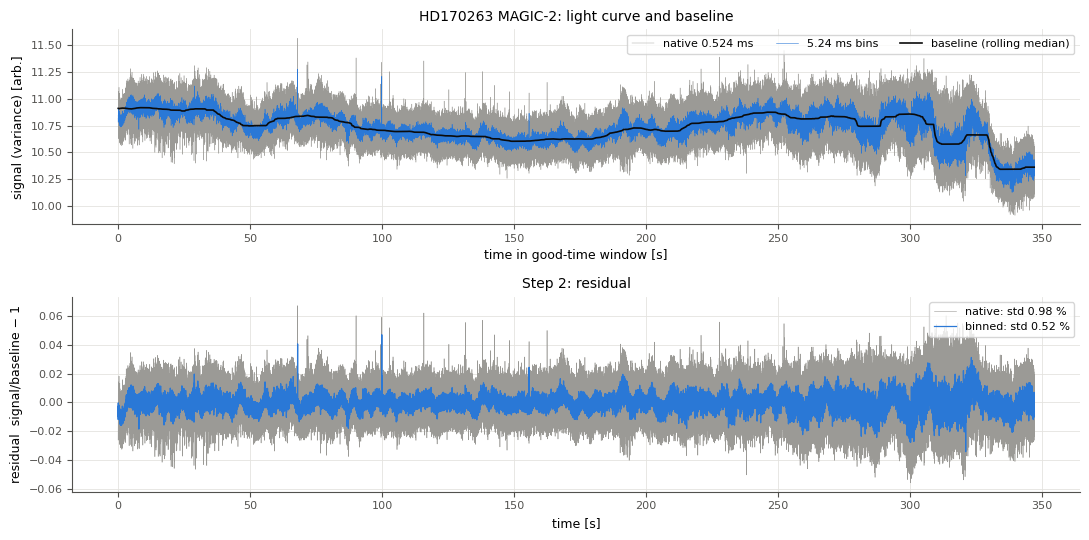

baseline native vs 5.24 ms: max |ratio - 1| = 1.1e-03


In [12]:
star, ch = FOCUS
r = RUNS[FOCUS]
tt, ti = r["bank"][RADIUS]
S = {}
for cad in ("native", "binned"):
    lc = r[cad]
    base, sg = compute_baseline_and_sigma(lc.time, lc.signal, DUR)
    mf, a = filter_output(lc, tt, ti, base, sg)
    M = len(mf.template_delta)
    w = window_samples(lc.dt, M)
    amp = sigma_current(a, lc.dt, M)
    S[cad] = dict(lc=lc, base=base, mf=mf, a=a, amp=amp, w=w, M=M, snr=a / amp)
    # sanity: this is exactly what the pipeline's own empirical normalisation returns
    ref = sliding_matched_filter_snr(lc.time, lc.signal, tt, ti, baseline=base, sigma=sg, normalization="empirical")
    assert np.allclose(ref.snr, S[cad]["snr"]) and np.allclose(ref.amp_sigma, amp)
    print(f"{cad:6s}: dt = {lc.dt*1e3:.3f} ms, template M = {M} samples, sigma window W = {w} samples "
          f"({w*lc.dt:.1f} s), block = W/8 = {w//8} samples ({w//8*lc.dt:.2f} s)")

t0 = S["binned"]["lc"].time[0]
fig, axs = plt.subplots(2, 1, figsize=(11, 5.5))
ax = style(axs[0])
ax.plot(S["native"]["lc"].time - t0, S["native"]["lc"].signal, color=CAD_COLOR["native"], lw=0.3, label="native 0.524 ms")
ax.plot(S["binned"]["lc"].time - t0, S["binned"]["lc"].signal, color=CAD_COLOR["binned"], lw=0.4, label="5.24 ms bins")
ax.plot(S["binned"]["lc"].time - t0, S["binned"]["base"], color=INK, lw=1.2, label="baseline (rolling median)")
ax.set(xlabel="time in good-time window [s]", ylabel="signal (variance) [arb.]",
       title=f"{star} {TEL[ch]}: light curve and baseline")
ax.legend(loc="upper right", ncol=3)
ax = style(axs[1])
z0, z1 = 100.0, 110.0
for cad in ("native", "binned"):
    lc = S[cad]["lc"] 
    #m = (lc.time - t0 >= z0) & (lc.time - t0 < z1)
    #ax.plot(lc.time[m] - t0, lc.signal[m] / S[cad]["base"][m] - 1, color=CAD_COLOR[cad],
    #        lw=0.4 if cad == "native" else 0.9, label=f"{cad}: std {np.std(lc.signal / S[cad]['base'] - 1)*100:.2f} %")
    ax.plot(lc.time - t0, lc.signal / S[cad]["base"] - 1, color=CAD_COLOR[cad],
            lw=0.4 if cad == "native" else 0.9, label=f"{cad}: std {np.std(lc.signal / S[cad]['base'] - 1)*100:.2f} %")
#ax.set(xlabel="time [s]", ylabel="residual  signal/baseline − 1", title="Step 2: residual (10 s zoom)")
ax.set(xlabel="time [s]", ylabel="residual  signal/baseline − 1", title="Step 2: residual")
ax.legend(loc="upper right")
finish(fig, "01_lightcurve_baseline_residual")
print(f"baseline native vs 5.24 ms: max |ratio - 1| = "
      f"{np.max(np.abs(np.interp(S['binned']['lc'].time, S['native']['lc'].time, S['native']['base']) / S['binned']['base'] - 1)):.1e}")

**Step 3: matched filter.** The template is the noiseless pattern minus 1 (`template_delta`),
point-sampled on each cadence's grid; it is 10× longer in samples at the native cadence. The output `a`
at lag *i* is the residual window starting at *i*, projected on the template and divided by its norm.
Each native sample is √10 noisier, but the native template norm is also √10 larger, so the native `a`
is √10 × the 5.24 ms one and the SNRs come out equal. Both are plotted on the 5.24 ms scale below.

native 3.1622776601683795 3.1622776601683795
binned 1.0 3.1622776601683795


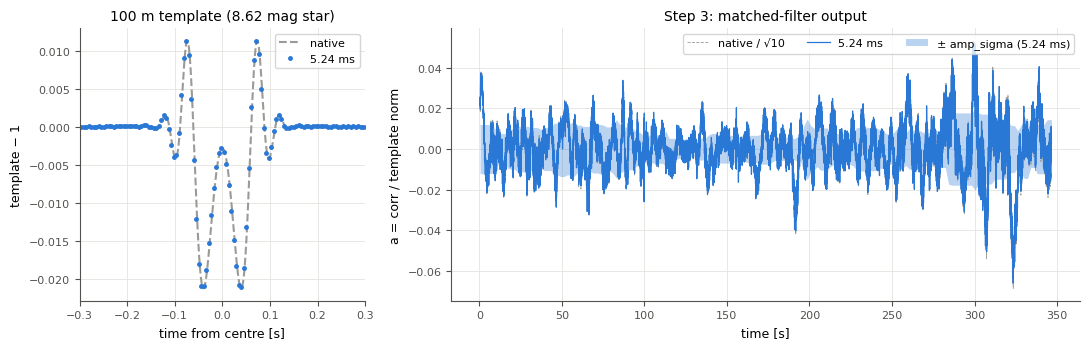

In [ ]:
fig, axs = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1, 2.2]})
ax = style(axs[0])
for cad in ("native", "binned"):
    d = S[cad]["mf"].template_delta
    dt = S[cad]["lc"].dt
    tk = np.arange(len(d)) * dt - len(d) * dt / 2
    if cad == "native":
        ax.plot(tk, d, color=CAD_COLOR[cad], ls='--', lw=1.5, label="native")
    else:
        ax.plot(tk, d, "o", ms=2.5, color=CAD_COLOR[cad], label="5.24 ms")
ax.set(xlim=(-0.3, 0.3), xlabel="time from centre [s]", ylabel="template − 1",
       title=f"{RADIUS:.0f} m template ({r['obs'].mag_B} mag star)")
ax.legend()
ax = style(axs[1])
for cad, scale in (("native", SQ10), ("binned", 1.0)):
    mf = S[cad]["mf"]
    ax.plot(mf.time - t0, S[cad]["a"] / scale, color=CAD_COLOR[cad], ls='--' if cad == "native" else '-', lw=0.6 if cad == "native" else 0.9,
            label="native / √10" if cad == "native" else "5.24 ms")
mfb = S["binned"]["mf"]
ax.fill_between(mfb.time - t0, -S["binned"]["amp"], S["binned"]["amp"], color=CAD_COLOR["binned"], alpha=0.32,
                lw=0, label="± amp_sigma (5.24 ms)")
ax.set(xlabel="time [s]", ylabel="a = corr / template norm", title="Step 3: matched-filter output")
ax.legend(loc="upper right", ncol=3)
finish(fig, "02_template_and_filter_output")

**Step 4: the noise estimate (`empirical_filter_sigma`).** The output is cut into consecutive blocks of
W/8 ≈ 2 s. Each block's robust scatter is taken as 1.4826 × median |a| (about zero, not about the block
median, so slow wander counts as noise). These block values are median-smoothed over 9 blocks (≈ 18 s)
and linearly interpolated back to every lag, which gives `amp_sigma`. The zoom below shows each stage.
Notice how smooth `a` is compared with the 2 s blocks: one block holds about one "wiggle" of the output.

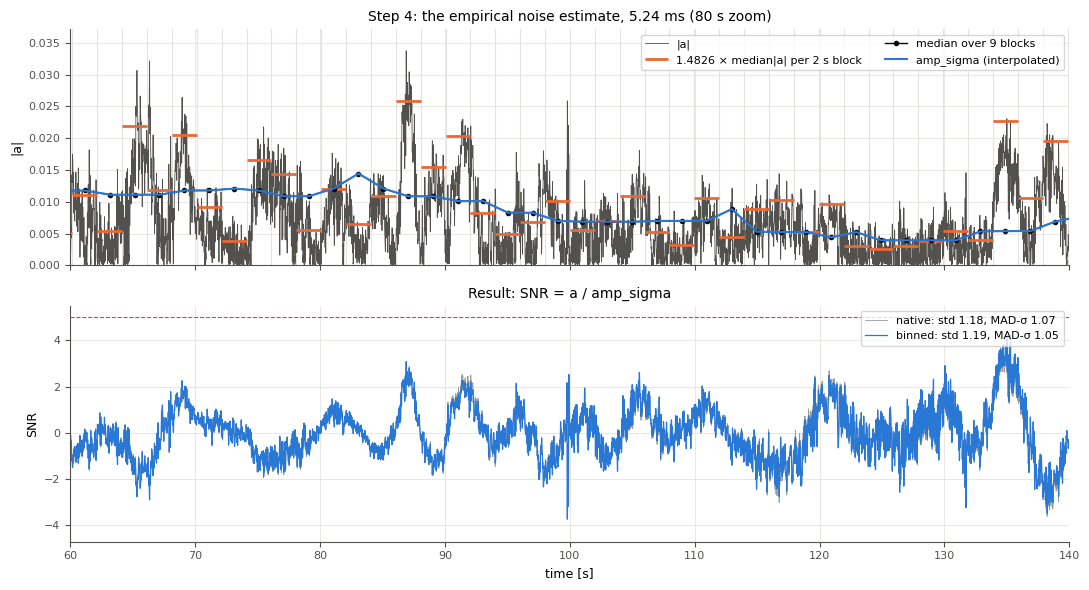

In [8]:
def anatomy(a, w):
    block = max(w // 8, 8)
    nb = len(a) // block
    mad = 1.4826 * np.median(np.abs(a[:nb * block].reshape(nb, block)), axis=1)
    smooth = median_filter(mad, size=max(w // block, 3) | 1, mode="reflect")
    centers = (np.arange(nb) + 0.5) * block
    return block, mad, smooth, centers

sb = S["binned"]; mfb = sb["mf"]
block, mad, smooth, centers = anatomy(sb["a"], sb["w"])
fig, axs = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
ax = style(axs[0])
ax.plot(mfb.time - t0, np.abs(sb["a"]), color=MUTED, lw=0.6, label="|a|")
for i in range(len(mad)):
    ax.hlines(mad[i], mfb.time[i * block] - t0, mfb.time[min((i + 1) * block, len(mfb.time) - 1)] - t0,
              color="#eb6834", lw=2, label="1.4826 × median|a| per 2 s block" if i == 0 else None)
ax.plot(mfb.time[centers.astype(int)] - t0, smooth, "o-", color=INK, ms=3, lw=1, label="median over 9 blocks")
ax.plot(mfb.time - t0, sb["amp"], color="#2a78d6", lw=1.5, label="amp_sigma (interpolated)")
for i in range(len(mad) + 1):
    if i * block < len(mfb.time):
        ax.axvline(mfb.time[i * block] - t0, color=GRID, lw=0.8, zorder=0)
zoom = (mfb.time - t0 >= 60) & (mfb.time - t0 <= 140)
ax.set(xlim=(60, 140), ylim=(0, 1.1 * np.abs(sb["a"][zoom]).max()), ylabel="|a|",
       title="Step 4: the empirical noise estimate, 5.24 ms (80 s zoom)")
ax.legend(loc="upper right", ncol=2)
ax = style(axs[1])
for cad in ("native", "binned"):
    ax.plot(S[cad]["mf"].time - t0, S[cad]["snr"], color=CAD_COLOR[cad], lw=0.6 if cad == "native" else 0.9,
            label=f"{cad}: std {np.std(S[cad]['snr']):.2f}, MAD-σ {mad_sigma(S[cad]['snr']):.2f}")
ax.axhline(5, color="#c2408a", lw=0.8, ls="--")
ax.set(ylim=(-1.1 * np.abs(sb["snr"][zoom]).max(), max(5.5, 1.1 * np.abs(sb["snr"][zoom]).max())),
       xlabel="time [s]", ylabel="SNR", title="Result: SNR = a / amp_sigma")
ax.legend(loc="upper right")
finish(fig, "03_estimator_anatomy")

## 2. Native vs 5.24 ms on all channel-runs

The same chain is run at both cadences on all 12 channel-runs, with the 100 m template of each star's
bank. For each run, compare the baselines, the filter outputs (native scaled by 1/√10 and interpolated
onto the 5.24 ms lags), and the two `amp_sigma`s. If the estimator were as stable as the data, the last
ratio would be ≈1 everywhere.

In [7]:
STACK = {}
rows = []
for key, rr in RUNS.items():
    tt_, ti_ = rr["bank"][RADIUS]
    st = {}
    for cad in ("native", "binned"):
        lc = rr[cad]
        base, sg = compute_baseline_and_sigma(lc.time, lc.signal, DUR)
        mf, a = filter_output(lc, tt_, ti_, base, sg)
        M = len(mf.template_delta)
        st[cad] = dict(lc=lc, base=base, sg=sg, mf=mf, a=a, M=M, w=window_samples(lc.dt, M),
                       amp=sigma_current(a, lc.dt, M))
    STACK[key] = st
    n_, b_ = st["native"], st["binned"]
    t5 = b_["mf"].time
    an = np.interp(t5, n_["mf"].time, n_["a"]) / SQ10
    ratio = np.interp(t5, n_["mf"].time, n_["amp"]) / SQ10 / b_["amp"]
    rows.append({"star": key[0], "telescope": TEL[key[1]],
                 "baseline max|Δ|": np.max(np.abs(np.interp(b_["lc"].time, n_["lc"].time, n_["base"]) / b_["base"] - 1)),
                 "output corr": np.corrcoef(an, b_["a"])[0, 1],
                 "output rms ratio": np.std(an) / np.std(b_["a"]),
                 "rms(diff)/rms": np.std(an - b_["a"]) / np.std(b_["a"]),
                 "σ ratio/√10 median": np.median(ratio),
                 "σ ratio p5": np.percentile(ratio, 5), "σ ratio p95": np.percentile(ratio, 95)})
CAD = pd.DataFrame(rows)
display(CAD.round(4))
f = CAD.loc[(CAD.star == FOCUS[0]) & (CAD.telescope == TEL[FOCUS[1]])].iloc[0]
print(f"check vs the earlier scratch numbers (HD170263 MAGIC-2): baseline {f['baseline max|Δ|']:.1e} (~1e-3), "
      f"output corr {f['output corr']:.4f} (~0.998), σ ratio p5-p95 {f['σ ratio p5']:.3f}-{f['σ ratio p95']:.3f} (~0.89-1.14)")

,star,telescope,baseline max|Δ|,output corr,output rms ratio,rms(diff)/rms,σ ratio/√10 median,σ ratio p5,σ ratio p95
0,HD170263,MAGIC-2,0.0011,0.9980,1.0227,0.0672,0.9909,0.8879,1.1352
1,HD170263,LST-1,0.0118,0.9976,0.9978,0.0697,1.0205,0.8808,1.2617
2,HD170263,MAGIC-1,0.0030,0.9990,1.0120,0.0457,1.0154,0.8790,1.1779
3,HD176914,MAGIC-2,0.0006,0.9983,0.9994,0.0575,0.9466,0.8949,1.0186
4,HD176914,LST-1,0.0022,0.9975,1.0174,0.0735,0.9970,0.8806,1.0992
5,HD176914,MAGIC-1,0.0007,0.9986,1.0047,0.0541,1.0176,0.9034,1.1128
6,HD196243,MAGIC-2,0.0012,0.9997,0.9980,0.0237,1.0095,0.9864,1.1043
7,HD196243,LST-1,0.0018,0.9993,0.9972,0.0361,1.0215,0.8735,1.0997
8,HD196243,MAGIC-1,0.0013,0.9984,0.9934,0.0573,0.9489,0.8877,1.0991
9,HD199102,MAGIC-2,0.0015,0.9997,1.0004,0.0229,1.0129,0.9466,1.0930


check vs the earlier scratch numbers (HD170263 MAGIC-2): baseline 1.1e-03 (~1e-3), output corr 0.9980 (~0.998), σ ratio p5-p95 0.888-1.135 (~0.89-1.14)


The baselines agree to ~0.1 % and the filter outputs are nearly identical (correlation ≳ 0.99). Yet the
two noise estimates still differ by ±10 % or more (5–95 %). Below: that ratio along the run for the
three telescopes on HD170263, and the native noise spectrum. The PSD shows that the band the 10-record
binning removes (> 95 Hz) is *quieter* than the signal band and holds no signal (f99 ≲ 31 Hz), so the
filter outputs agree and the cadence is not the issue.

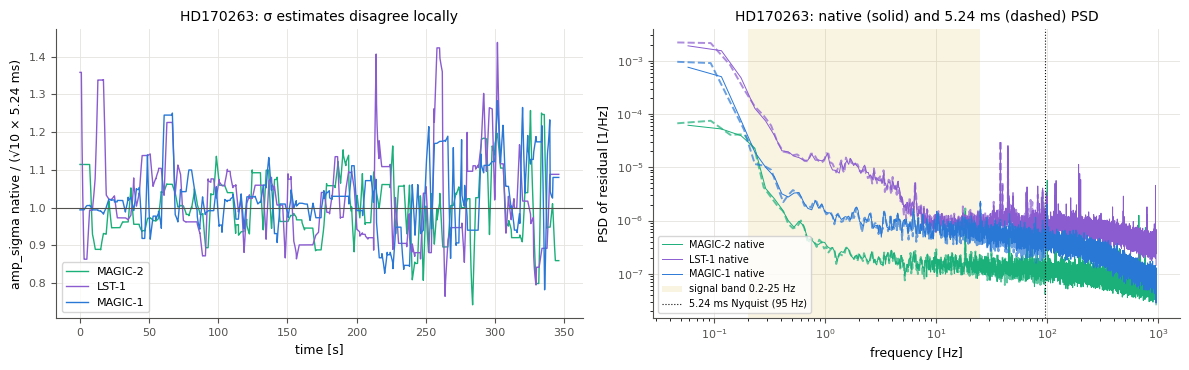

,telescope,S(1-10 Hz)/S(500-950),S(30-90 Hz)/S(500-950),S(100-300 Hz)/S(500-950)
0,MAGIC-2,2.87,2.05,1.67
1,LST-1,5.15,2.24,1.82
2,MAGIC-1,8.32,4.62,3.13


In [8]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = style(axs[0])
for c in night.channels:
    st = STACK[(FOCUS[0], c)]
    t5 = st["binned"]["mf"].time
    ratio = np.interp(t5, st["native"]["mf"].time, st["native"]["amp"]) / SQ10 / st["binned"]["amp"]
    ax.plot(t5 - t5[0], ratio, color=TEL_COLOR[c], lw=1, label=TEL[c])
ax.axhline(1, color=MUTED, lw=0.8)
ax.set(xlabel="time [s]", ylabel="amp_sigma native / (√10 × 5.24 ms)", title=f"{FOCUS[0]}: σ estimates disagree locally")
ax.legend()
ax = style(axs[1])
psd_rows = []
for c in night.channels:
    st = STACK[(FOCUS[0], c)]
    for cad, nper in (("native", 2 ** 15), ("binned", 2 ** 12)):
        lc = st[cad]["lc"]
        x = lc.signal / st[cad]["base"] - 1
        fr, P = welch(x, fs=1 / lc.dt, nperseg=nper, detrend="linear")
        if cad == "native":
            ax.loglog(fr[1:], P[1:], color=TEL_COLOR[c], lw=0.7, label=f"{TEL[c]} native")
            band = lambda lo, hi: np.median(P[(fr >= lo) & (fr < hi)])
            psd_rows.append({"telescope": TEL[c], "S(1-10 Hz)/S(500-950)": band(1, 10) / band(500, 950),
                             "S(30-90 Hz)/S(500-950)": band(30, 90) / band(500, 950),
                             "S(100-300 Hz)/S(500-950)": band(100, 300) / band(500, 950)})
        else:
            ax.loglog(fr[1:], P[1:], color=TEL_COLOR[c], lw=1.4, ls="--", alpha=0.7)
ax.axvspan(0.2, 25, color="#d4a017", alpha=0.12, lw=0, label="signal band 0.2-25 Hz")
ax.axvline(1 / (2 * 10 * RUNS[FOCUS]["native"].dt), color=INK, lw=0.8, ls=":", label="5.24 ms Nyquist (95 Hz)")
ax.set(xlabel="frequency [Hz]", ylabel="PSD of residual [1/Hz]", title=f"{FOCUS[0]}: native (solid) and 5.24 ms (dashed) PSD")
ax.legend(loc="lower left", fontsize=7)
finish(fig, "04_native_vs_binned")
display(pd.DataFrame(psd_rows).round(2))

## 3. The same estimator on a changed sampling grid

If the inputs are (almost) the same, where does the disagreement come from? Three tests on the
filter output, all with the pipeline estimator (F0):

* **(a)** the native output, scaled by 1/√10 and resampled onto the 5.24 ms lags, put through the
  5.24 ms estimator: the estimator and grid are the same, only the input changes slightly;
* **(b)** the 5.24 ms output, upsampled onto the native lags, put through the native-grid estimator:
  the input is the same, only the grid changes;
* **(c)** the *identical* 5.24 ms output, with only the block edges moved (drop the first *k* lags,
  i.e. shift by 0.1–2 s).

Each test gives a ratio to the original 5.24 ms `amp_sigma` at the same lags. A shift of exactly one
block (1.99 s) recovers almost the same partition, so the ratio returns to ≈1 there: the estimate
depends on the block *phase*, nothing else.

In [9]:
SHIFTS_S = (0.1, 0.2, 0.5, 1.0, 1.5, 2.0)
rows, shift_ratios = [], {}
for key, st in STACK.items():
    n_, b_ = st["native"], st["binned"]
    t5, a5, s5, dt5 = b_["mf"].time, b_["a"], b_["amp"], b_["lc"].dt
    an = np.interp(t5, n_["mf"].time, n_["a"]) / SQ10
    ra = empirical_filter_sigma(an, b_["w"]) / s5
    a5_up = np.interp(n_["mf"].time, t5, a5)
    rb = np.interp(t5, n_["mf"].time, empirical_filter_sigma(a5_up, n_["w"])) / s5
    row = {"star": key[0], "telescope": TEL[key[1]],
           "(a) p5": np.percentile(ra, 5), "(a) p95": np.percentile(ra, 95),
           "(b) p5": np.percentile(rb, 5), "(b) p95": np.percentile(rb, 95)}
    for sh in SHIFTS_S:
        k = int(round(sh / dt5))
        rc = empirical_filter_sigma(a5[k:], b_["w"]) / s5[k:]
        shift_ratios[(key, sh)] = rc
        row[f"(c) {sh:g} s p5"] = np.percentile(rc, 5)
        row[f"(c) {sh:g} s p95"] = np.percentile(rc, 95)
    rows.append(row)
GRIDTEST = pd.DataFrame(rows)
display(GRIDTEST.round(3))
f = GRIDTEST.loc[(GRIDTEST.star == FOCUS[0]) & (GRIDTEST.telescope == TEL[FOCUS[1]])].iloc[0]
print(f"check (HD170263 MAGIC-2): 1 s block shift p5-p95 = {f['(c) 1 s p5']:.3f}-{f['(c) 1 s p95']:.3f} (scratch: 0.78-1.43)")

,star,telescope,(a) p5,(a) p95,(b) p5,(b) p95,(c) 0.1 s p5,(c) 0.1 s p95,(c) 0.2 s p5,(c) 0.2 s p95,(c) 0.5 s p5,(c) 0.5 s p95,(c) 1 s p5,(c) 1 s p95,(c) 1.5 s p5,(c) 1.5 s p95,(c) 2 s p5,(c) 2 s p95
0,HD170263,MAGIC-2,0.920,1.111,0.897,1.115,0.919,1.059,0.867,1.155,0.832,1.264,0.784,1.423,0.788,1.249,0.984,1.004
1,HD170263,LST-1,0.902,1.174,0.893,1.132,0.917,1.087,0.886,1.160,0.801,1.309,0.796,1.224,0.801,1.217,0.994,1.006
2,HD170263,MAGIC-1,0.950,1.077,0.895,1.174,0.931,1.084,0.879,1.175,0.821,1.380,0.761,1.500,0.732,1.248,0.991,1.006
3,HD176914,MAGIC-2,0.914,1.017,0.981,1.010,0.926,1.018,0.953,1.070,0.929,1.140,0.869,1.184,0.935,1.231,0.994,1.007
4,HD176914,LST-1,0.886,1.078,0.968,1.012,0.908,1.121,0.922,1.201,0.864,1.526,0.858,1.334,0.607,1.202,0.991,1.160
5,HD176914,MAGIC-1,0.933,1.116,0.985,1.003,0.917,1.055,0.917,1.170,0.836,1.294,0.878,1.587,0.918,1.276,0.967,1.000
6,HD196243,MAGIC-2,1.003,1.114,0.955,1.011,0.897,1.019,0.729,1.157,0.803,1.332,0.793,1.347,0.650,1.266,0.788,1.003
7,HD196243,LST-1,0.857,1.103,0.969,1.028,0.916,1.076,0.901,1.112,0.672,1.212,0.593,1.253,0.733,1.169,0.993,1.098
8,HD196243,MAGIC-1,0.881,1.093,0.973,1.014,0.934,1.054,0.891,1.121,0.659,1.310,0.714,1.278,0.708,1.213,0.994,1.123
9,HD199102,MAGIC-2,0.948,1.034,0.970,1.091,0.949,1.139,0.902,1.227,0.830,1.503,0.766,1.658,0.690,1.589,0.996,1.039


check (HD170263 MAGIC-2): 1 s block shift p5-p95 = 0.784-1.423 (scratch: 0.78-1.43)


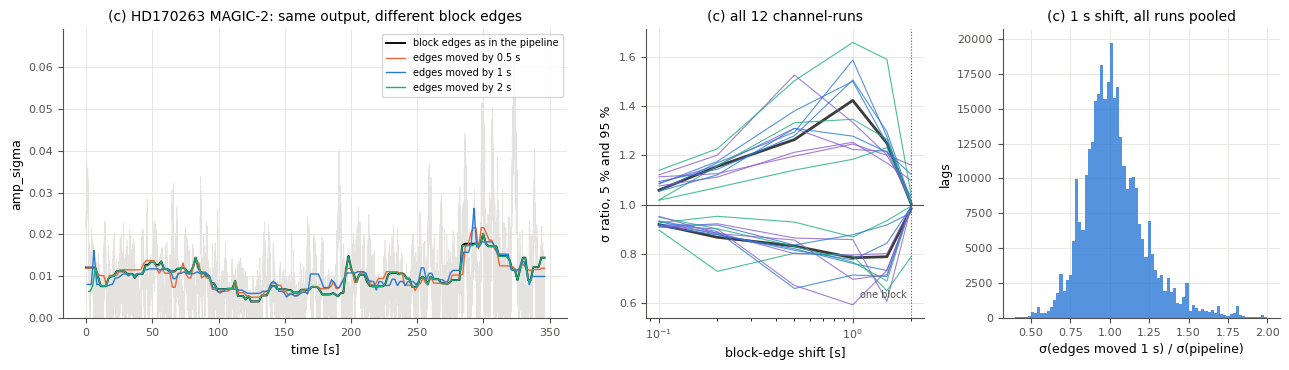

In [10]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8), gridspec_kw={"width_ratios": [2, 1.1, 1.1]})
ax = style(axs[0])
b_ = STACK[FOCUS]["binned"]; t5 = b_["mf"].time
ax.plot(t5 - t5[0], b_["amp"], color=INK, lw=1.4, label="block edges as in the pipeline")
for sh, colr in zip((0.5, 1.0, 2.0), ("#eb6834", "#2a78d6", "#1baf7a")):
    k = int(round(sh / b_["lc"].dt))
    ax.plot(t5[k:] - t5[0], empirical_filter_sigma(b_["a"][k:], b_["w"]), color=colr, lw=1, label=f"edges moved by {sh:g} s")
ax.plot(t5 - t5[0], np.abs(b_["a"]), color=GRID, lw=0.5, zorder=0)
ax.set(xlabel="time [s]", ylabel="amp_sigma", ylim=(0, None),
       title=f"(c) {FOCUS[0]} {TEL[FOCUS[1]]}: same output, different block edges")
ax.legend(loc="upper right", fontsize=7)
ax = style(axs[1])
for key in STACK:
    q = [(np.percentile(shift_ratios[(key, sh)], 5), np.percentile(shift_ratios[(key, sh)], 95)) for sh in SHIFTS_S]
    lw, colr = (2, INK) if key == FOCUS else (0.8, TEL_COLOR[key[1]])
    ax.plot(SHIFTS_S, [x[1] for x in q], color=colr, lw=lw, alpha=0.8)
    ax.plot(SHIFTS_S, [x[0] for x in q], color=colr, lw=lw, alpha=0.8)
ax.axhline(1, color=MUTED, lw=0.8)
ax.axvline((STACK[FOCUS]["binned"]["w"] // 8) * STACK[FOCUS]["binned"]["lc"].dt, color=MUTED, lw=0.8, ls=":")
ax.text(1.9, 0.62, "one block", color=MUTED, fontsize=7, ha="right")
ax.set(xscale="log", xlabel="block-edge shift [s]", ylabel="σ ratio, 5 % and 95 %", title="(c) all 12 channel-runs")
ax = style(axs[2])
pool = np.concatenate([shift_ratios[(k, 1.0)] for k in STACK])
ax.hist(pool, bins=np.linspace(0.4, 2.0, 81), color="#2a78d6", alpha=0.8)
ax.set(xlabel="σ(edges moved 1 s) / σ(pipeline)", ylabel="lags", title="(c) 1 s shift, all runs pooled")
finish(fig, "05_block_edge_shift")

### (d) Why: the filter output is correlated over a block or longer

The integrated autocorrelation time τ of `a` measures how many independent values a block or window
holds: N ≈ length / τ. On these runs τ ≈ 1.5–4 s, so a 2 s block holds 0.5–1.4 independent values and
the 9-block window 4.5–12. For N independent Gaussian values the MAD-based σ has a relative scatter of about
1.17/√N (it is ~1.65× noisier than the standard deviation). The median over 9 block values helps less
than it would with independent blocks, because neighbouring blocks share correlated stretches.

,star,telescope,τ_int [s],block [s],N per block,N per 9-block window,1.17/√N (window)
0,HD170263,MAGIC-2,2.40,1.99,0.83,7.48,0.43
1,HD170263,LST-1,3.57,1.99,0.56,5.03,0.52
2,HD170263,MAGIC-1,3.61,1.99,0.55,4.97,0.52
3,HD176914,MAGIC-2,1.45,1.99,1.37,12.34,0.33
4,HD176914,LST-1,3.46,1.99,0.58,5.18,0.51
5,HD176914,MAGIC-1,2.05,1.99,0.97,8.75,0.40
6,HD196243,MAGIC-2,2.46,1.99,0.81,7.29,0.43
7,HD196243,LST-1,3.88,1.99,0.51,4.62,0.54
8,HD196243,MAGIC-1,3.98,1.99,0.50,4.50,0.55
9,HD199102,MAGIC-2,3.48,1.99,0.57,5.15,0.52


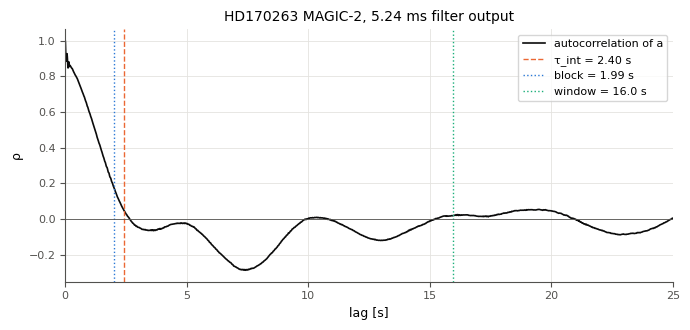

In [11]:
rows = []
for key, st in STACK.items():
    b_ = st["binned"]
    tau, ac = int_corr_time(b_["a"], b_["lc"].dt)
    block_s = (b_["w"] // 8) * b_["lc"].dt
    win_s = 9 * block_s
    rows.append({"star": key[0], "telescope": TEL[key[1]], "τ_int [s]": tau, "block [s]": block_s,
                 "N per block": block_s / tau, "N per 9-block window": win_s / tau,
                 "1.17/√N (window)": 1.17 / np.sqrt(win_s / tau)})
    if key == FOCUS:
        ac_focus, tau_focus, dt_focus, block_focus = ac, tau, b_["lc"].dt, block_s
TAU = pd.DataFrame(rows)
display(TAU.round(2))
fig, ax = plt.subplots(figsize=(7, 3.4)); style(ax)
lags = np.arange(len(ac_focus)) * dt_focus
ax.plot(lags, ac_focus, color=INK, lw=1.2, label="autocorrelation of a")
ax.axvline(tau_focus, color="#eb6834", lw=1, ls="--", label=f"τ_int = {tau_focus:.2f} s")
ax.axvline(block_focus, color="#2a78d6", lw=1, ls=":", label=f"block = {block_focus:.2f} s")
ax.axvline(20 * DUR, color="#1baf7a", lw=1, ls=":", label=f"window = {20*DUR:.1f} s")
ax.axhline(0, color=MUTED, lw=0.6)
ax.set(xlim=(0, 25), xlabel="lag [s]", ylabel="ρ", title=f"{FOCUS[0]} {TEL[FOCUS[1]]}, 5.24 ms filter output")
ax.legend()
finish(fig, "06_autocorrelation")

## 4. What it does to the SNR and the false-alarm rate

From here on, everything is at the search cadence (5.24 ms) with the full per-star bank, as in
`mimic.run_mimic`. To separate estimator noise from real changes in the noise, we need a case where the
true σ is known. **Gaussian surrogates** provide one: `phase_randomized_lightcurve` keeps each run's
noise spectrum exactly but makes it stationary. On a surrogate the true σ of the filter output is a
single number per run and template, measured by pooling |a| over a few pilot surrogates. Dividing by
it gives the **oracle** SNR: what the search would give with a perfect noise estimate.

Each surrogate is seeded by (run, index), so sections 4–6 see the same noise realisations.

In [12]:
RUN_INDEX = {key: i for i, key in enumerate(RUNS)}

def surrogate(key, k):
    return phase_randomized_lightcurve(RUNS[key]["binned"], np.random.default_rng([SEED, RUN_INDEX[key], k]))

def bank_outputs(lc, bank):
    """{radius: (MatchedFilterResult, a)} for every template of the bank, one shared baseline."""
    base, sg = compute_baseline_and_sigma(lc.time, lc.signal, DUR)
    return {R: filter_output(lc, tt_, ti_, base, sg) for R, (tt_, ti_) in bank.items()}

def candidates(outs, amps, thr=SNR_FLOOR):
    """Best template per time, deduplicated by the template span: the loop of mimic.search_lightcurve."""
    best = []
    for R, (mf, a) in outs.items():
        mfE = replace(mf, snr=a / amps[R], amp_sigma=amps[R], normalization="custom")
        for c in find_candidates(mfE, snr_threshold=thr, chi2_weighting="empirical"):
            best.append({"time_s": c.time_s, "snr": c.snr, "chi2_reduced": c.chi2_reduced, "radius_m": R})
    kept = []
    for row in sorted(best, key=lambda x: -x["snr"]):
        if all(abs(row["time_s"] - k_["time_s"]) >= DUR for k_ in kept):
            kept.append(row)
    return kept

# true sigma of every (run, template) from 4 pilot surrogates (indices >= 1000, not reused below)
SIG_TRUE = {}
for key, rr in RUNS.items():
    pooled = {R: [] for R in rr["bank"]}
    for k in range(1000, 1004):
        for R, (mf, a) in bank_outputs(surrogate(key, k), rr["bank"]).items():
            pooled[R].append(np.abs(a))
    for R, x in pooled.items():
        SIG_TRUE[(key, R)] = 1.4826 * np.median(np.concatenate(x))

def amps_for(est, outs, key):
    if est == "oracle":
        return {R: np.full(len(a), SIG_TRUE[(key, R)]) for R, (mf, a) in outs.items()}
    return {R: ESTIMATORS[est](a, mf.dt_s, len(mf.template_delta)) for R, (mf, a) in outs.items()}

### 4.1 Search: real data and surrogates, every estimator

One pass over the 12 channel-runs: the real light curve and `N_SURR` surrogates, each searched with
every estimator (and with the oracle on surrogates). For each search we keep the candidates (SNR ≥ 3,
best template per time), the calibration of the SNR trace (std and MAD-σ, 100 m template; both should
be ≈1), and on surrogates the ratio σ̂/σ_true sampled once per second.

In [13]:
t_ = _time.time()
CAND, CALIB, RATIO = [], [], {e: [] for e in ESTIMATORS}
for key, rr in RUNS.items():
    for kind, k in [("real", -1)] + [("surrogate", k) for k in range(N_SURR)]:
        lc = rr["binned"] if kind == "real" else surrogate(key, k)
        outs = bank_outputs(lc, rr["bank"])
        for est in list(ESTIMATORS) + (["oracle"] if kind == "surrogate" else []):
            amps = amps_for(est, outs, key)
            for c in candidates(outs, amps):
                CAND.append({"star": key[0], "channel": key[1], "kind": kind, "k": k, "est": est, **c})
            mf, a = outs[RADIUS]
            z = a / amps[RADIUS]
            CALIB.append({"star": key[0], "channel": key[1], "kind": kind, "k": k, "est": est,
                          "snr_std": np.std(z), "snr_mad": mad_sigma(z)})
            if kind == "surrogate" and est != "oracle":
                step = int(round(1.0 / mf.dt_s))
                RATIO[est].append(amps[RADIUS][::step] / SIG_TRUE[(key, RADIUS)])
CAND, CALIB = pd.DataFrame(CAND), pd.DataFrame(CALIB)
RATIO = {e: np.concatenate(v) for e, v in RATIO.items()}
print(f"searched {len(RUNS)} channel-runs x (1 real + {N_SURR} surrogates) x {len(ESTIMATORS)} estimators "
      f"in {_time.time() - t_:.0f} s; {len(CAND)} candidates above SNR {SNR_FLOOR}")

searched 12 channel-runs x (1 real + 40 surrogates) x 7 estimators in 233 s; 19762 candidates above SNR 3.0


### 4.2 How wrong is σ̂ on stationary noise?

On surrogates the true σ is known, so the spread of σ̂/σ_true is pure estimator noise. For the
pipeline (F0) it can be compared with the 1.17/√N estimate of section 3(d). Because SNR = a/σ̂, a σ̂ that
is 20 % low turns a 4σ fluctuation into SNR 5.

,estimator,median σ̂/σ_true,p5,p95,rms log
0,F0 current,0.933,0.507,2.013,0.422
1,F1 one block,1.013,0.655,1.637,0.275
2,F2 sliding 16 s,1.001,0.558,2.051,0.395
3,F3 sliding 30 s,1.005,0.637,1.710,0.302
4,F3 sliding 60 s,1.008,0.715,1.463,0.218
5,F3 sliding 120 s,1.008,0.782,1.306,0.156
6,F3 whole run,0.999,0.874,1.184,0.092


section 3(d) prediction for F0, 1.17/sqrt(N) over the 12 runs: median 0.52


snr_std           snr_mad          
kind                real surrogate    real surrogate
est                                                 
F0 current         1.159     1.133   1.046     1.057
F1 one block       1.270     1.106   0.994     0.999
F2 sliding 16 s    1.047     1.026   1.007     1.005
F3 sliding 120 s   1.378     1.138   1.002     0.997
F3 sliding 30 s    1.188     1.078   0.998     1.002
F3 sliding 60 s    1.274     1.119   1.007     0.999
F3 whole run       1.438     1.150   0.997     0.999
oracle               NaN     1.166     NaN     1.012

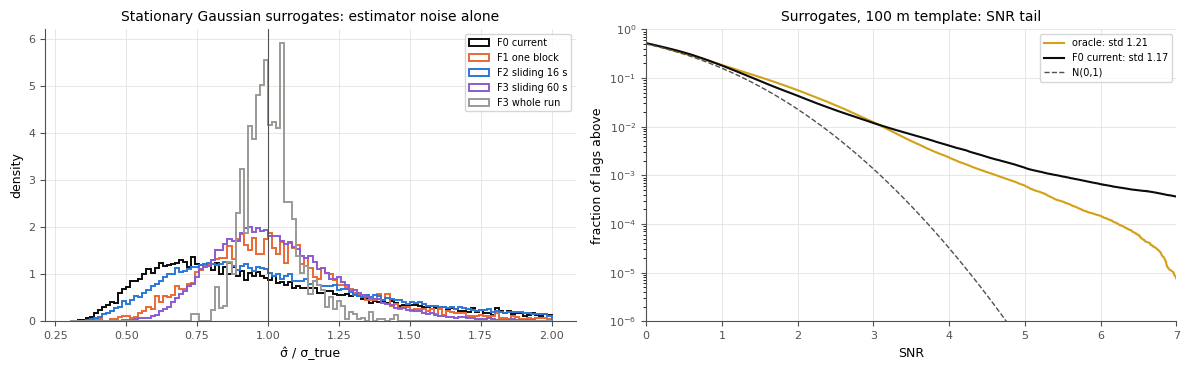

In [14]:
rows = []
for est, x in RATIO.items():
    rows.append({"estimator": est, "median σ̂/σ_true": np.median(x), "p5": np.percentile(x, 5),
                 "p95": np.percentile(x, 95), "rms log": np.std(np.log(x))})
SURR_SIGMA = pd.DataFrame(rows)
display(SURR_SIGMA.round(3))
print(f"section 3(d) prediction for F0, 1.17/sqrt(N) over the 12 runs: median {TAU['1.17/√N (window)'].median():.2f}")

cal = CALIB.groupby(["kind", "est"])[["snr_std", "snr_mad"]].median().unstack(0)
display(cal.round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
ax = style(axs[0])
bins = np.linspace(0.3, 2.0, 120)
for est in ("F0 current", "F1 one block", "F2 sliding 16 s", "F3 sliding 60 s", "F3 whole run"):
    ax.hist(RATIO[est], bins=bins, histtype="step", lw=1.4, color=EST_COLOR[est], density=True, label=est)
ax.axvline(1, color=MUTED, lw=0.8)
ax.set(xlabel="σ̂ / σ_true", ylabel="density", title="Stationary Gaussian surrogates: estimator noise alone")
ax.legend(fontsize=7)
ax = style(axs[1])
# SNR distribution of the 100 m template on surrogates: oracle vs pipeline, pooled
pool = {e: [] for e in ("oracle", "F0 current")}
for key, rr in RUNS.items():
    for k in range(min(N_SURR, 5)):
        outs = {RADIUS: filter_output(surrogate(key, k), *rr["bank"][RADIUS])}
        for e in pool:
            mf, a = outs[RADIUS]
            pool[e].append(a / amps_for(e, outs, key)[RADIUS])
xs = np.linspace(-7, 7, 141)
for e, zs in pool.items():
    z = np.concatenate(zs)
    srt = np.sort(z)
    surv = 1.0 - np.arange(len(srt)) / len(srt)
    ax.semilogy(srt, surv, color=EST_COLOR[e], lw=1.5, label=f"{e}: std {np.std(z):.2f}")
ax.semilogy(xs, ndtr(-xs), color=MUTED, ls="--", lw=1, label="N(0,1)")
ax.set(xlim=(0, 7), ylim=(1e-6, 1), xlabel="SNR", ylabel="fraction of lags above",
       title="Surrogates, 100 m template: SNR tail")
ax.legend(fontsize=7)
finish(fig, "07_sigma_on_surrogates")

### 4.3 A second source of tails: the rolling-median baseline

The right panel above shows that even the **oracle** SNR (true σ, stationary Gaussian surrogates) has
tails orders of magnitude above N(0,1). A linear filter of Gaussian noise is Gaussian, so the tails must
come from a non-linear step, and that step is the baseline. A rolling median of red noise switches
between values in jumps, and the pipeline's decimated version (0.25 s block means, median,
linear interpolation) adds kinks. The template has a non-zero mean, so it responds to these steps.
Below, the same surrogates are detrended three ways, with the true σ of each case as normalisation:
the pipeline's decimated median, the exact median (`decimate=1`), and a running mean over the same
16 s.

The steps are visible in the baseline of the first figure (e.g. around 285, 310 and 330 s).

A running mean is not a drop-in replacement. The median was chosen because a dip or a glitch hardly
moves it, while a mean is pulled by the event itself and by outliers. This is a pointer for later work;
the rest of the notebook keeps the pipeline baseline.

kurtosis of a       std/MAD of a      
                                      mean   std         mean   std
baseline                                                           
median, decimated (pipeline)          0.95  0.39         1.16  0.04
median, exact                         0.51  0.33         1.06  0.02
running mean 16 s                     0.01  0.18         0.99  0.02

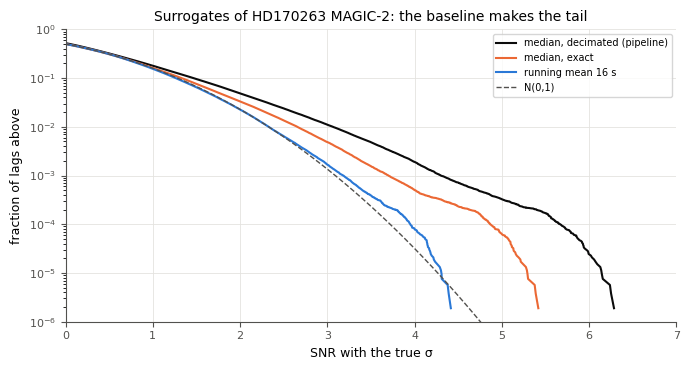

In [15]:
BASELINES = {
    "median, decimated (pipeline)": lambda lc: compute_baseline_and_sigma(lc.time, lc.signal, DUR)[0],
    "median, exact": lambda lc: compute_baseline_and_sigma(lc.time, lc.signal, DUR, decimate=1)[0],
    "running mean 16 s": lambda lc: uniform_filter1d(lc.signal, int(round(20 * DUR / lc.dt)), mode="reflect"),
}
BASE_COLOR = dict(zip(BASELINES, ("#0b0b0b", "#eb6834", "#2a78d6")))
tt_, ti_ = RUNS[FOCUS]["bank"][RADIUS]
zs, rows = {n: [] for n in BASELINES}, []
for k in range(min(N_SURR, 8)):
    sur = surrogate(FOCUS, k)
    for n, fn in BASELINES.items():
        b = fn(sur)
        a = filter_output(sur, tt_, ti_, b, np.ones_like(b))[1]      # sigma is unused with a given baseline
        zs[n].append(a)
        rows.append({"baseline": n, "k": k, "kurtosis of a": kurtosis(a),
                     "std/MAD of a": np.std(a) / (1.4826 * np.median(np.abs(a)))})
display(pd.DataFrame(rows).groupby("baseline")[["kurtosis of a", "std/MAD of a"]].agg(["mean", "std"]).round(2))

fig, ax = plt.subplots(figsize=(7, 3.8)); style(ax)
for n, lst in zs.items():
    a = np.concatenate(lst)
    z = np.sort(a / (1.4826 * np.median(np.abs(a))))
    ax.semilogy(z, 1.0 - np.arange(len(z)) / len(z), color=BASE_COLOR[n], lw=1.5, label=n)
ax.semilogy(xs, ndtr(-xs), color=MUTED, ls="--", lw=1, label="N(0,1)")
ax.set(xlim=(0, 7), ylim=(1e-6, 1), xlabel="SNR with the true σ", ylabel="fraction of lags above",
       title=f"Surrogates of {FOCUS[0]} {TEL[FOCUS[1]]}: the baseline makes the tail")
ax.legend(fontsize=7)
finish(fig, "07b_baseline_tails")

### 4.4 False-alarm rates

* **Single telescope:** candidates per telescope-hour above a given SNR, for real data (~0.5
  telescope-hours, so only rates ≳ 5/h are measurable) and for the surrogates.
* **2-of-3 coincidences** within ±`TOL`, SNR = the weaker member (`mimic._event_rows`). The real
  background comes from time slides (`accidental_coincidence_rate`, each telescope's candidate list
  shifted circularly), and the surrogate background from independent surrogates per telescope.

The oracle curve on surrogates is what a perfect σ would give. Any estimator above it is paying FAR
for its own noise.

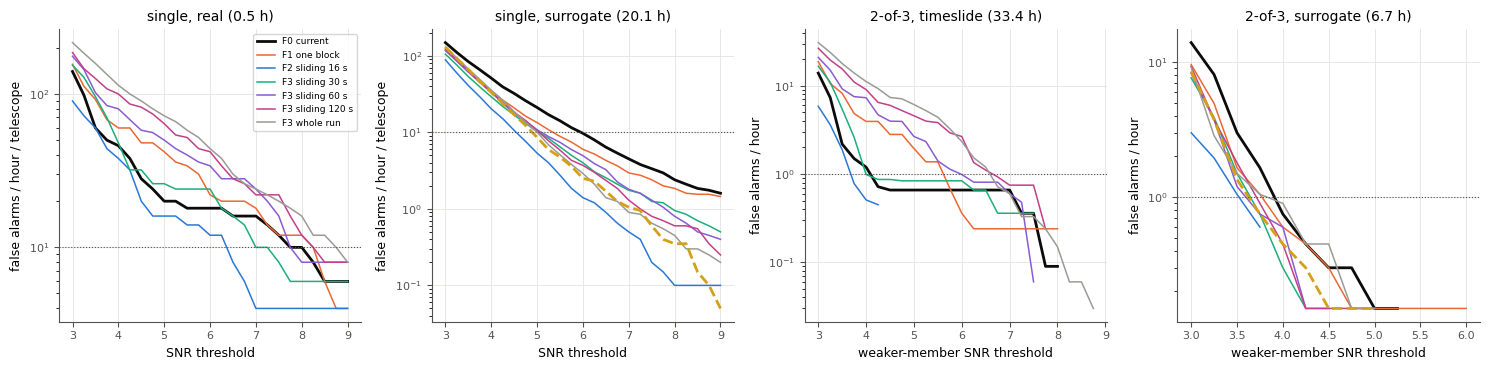

,single real thr @10/h,single real thr @30/h,single surrogate thr @10/h,2-of-3 timeslide thr @1/h,2-of-3 surrogate thr @1/h
estimator,,,,,
F0 current,7.55,4.35,5.92,4.04,3.91
F1 one block,8.18,5.74,5.34,5.74,3.83
F2 sliding 16 s,6.27,4.25,4.53,3.53,3.55
F3 sliding 30 s,6.97,4.54,5.04,3.97,3.59
F3 sliding 60 s,7.73,6.19,5.10,5.81,3.54
F3 sliding 120 s,8.23,6.40,5.02,6.66,3.66
F3 whole run,8.68,6.48,5.00,6.70,3.79
oracle,NaN,NaN,4.90,NaN,3.62


In [16]:
SNR_GRID = np.round(np.arange(3.0, 9.01, 0.25), 2)
H_SINGLE = {"real": sum(LIVE.values()) * 3 / 3600, "surrogate": sum(LIVE.values()) * 3 * N_SURR / 3600}
H_COINC = {"timeslide": sum(LIVE.values()) * N_SHIFTS / 3600, "surrogate": sum(LIVE.values()) * N_SURR / 3600}

def coincidences(cand, kinds_k, ests):
    """2-of-3 events (min SNR) for each estimator from per-channel candidate tables."""
    ev = []
    for est in ests:
        for star in STARS:
            for kind, k in kinds_k:
                sub = cand[(cand.est == est) & (cand.star == star) & (cand.kind == kind) & (cand.k == k)]
                per_ch = {c: (sub[sub.channel == c].to_dict("records"), LIVE[star]) for c in night.channels}
                res = _telescope_results(per_ch)
                if kind == "real":
                    acc = accidental_coincidence_rate(res, TOL, LIVE[star], n_shifts=N_SHIFTS,
                                                      min_shift_s=max(5.0, 3.0 * TOL), seed=SEED)
                    ev += [{"est": est, "kind": "timeslide", "min_snr": s} for s in acc.event_min_snr]
                    ev += [{"est": est, "kind": "real", "min_snr": e["min_snr"]} for e in _event_rows(res, TOL)]
                else:
                    ev += [{"est": est, "kind": kind, "min_snr": e["min_snr"]} for e in _event_rows(res, TOL)]
    return pd.DataFrame(ev, columns=["est", "kind", "min_snr"])

EV = coincidences(CAND, [("real", -1)] + [("surrogate", k) for k in range(N_SURR)], list(ESTIMATORS) + ["oracle"])

def far_rows(cand, ev, est):
    out = {}
    for kind in ("real", "surrogate"):
        s = cand[(cand.est == est) & (cand.kind == kind)]["snr"].to_numpy()
        if not (est == "oracle" and kind == "real"):
            out[("single", kind)] = (s, H_SINGLE[kind])
    for kind in ("timeslide", "surrogate"):
        out[("2-of-3", kind)] = (ev[(ev.est == est) & (ev.kind == kind)]["min_snr"].to_numpy(), H_COINC[kind])
    return out

fig, axs = plt.subplots(1, 4, figsize=(15, 3.8), sharey=False)
panels = [("single", "real"), ("single", "surrogate"), ("2-of-3", "timeslide"), ("2-of-3", "surrogate")]
for ax, (scope, kind) in zip(axs, panels):
    style(ax)
    for est in list(ESTIMATORS) + ["oracle"]:
        if est == "oracle" and kind in ("real", "timeslide"):
            continue
        s, h = far_rows(CAND, EV, est)[(scope, kind)]
        rate = [(s >= g).sum() / h for g in SNR_GRID]
        ax.semilogy(SNR_GRID, np.where(np.array(rate) > 0, rate, np.nan), color=EST_COLOR[est],
                    lw=2 if est in ("F0 current", "oracle") else 1.1, ls="--" if est == "oracle" else "-", label=est)
    ax.axhline(FAR_SINGLE if scope == "single" else FAR_COINC, color=MUTED, lw=0.8, ls=":")
    ax.set(xlabel="SNR threshold" if scope == "single" else "weaker-member SNR threshold",
           ylabel="false alarms / hour" + (" / telescope" if scope == "single" else ""),
           title=f"{scope}, {kind} ({h:.1f} h)")
axs[0].legend(fontsize=6.5)
finish(fig, "08_far_curves")

rows = []
for est in list(ESTIMATORS) + ["oracle"]:
    fr = far_rows(CAND, EV, est)
    row = {"estimator": est}
    for (scope, kind), (s, h) in fr.items():
        if est == "oracle" and kind in ("real", "timeslide"):
            continue
        far = FAR_SINGLE if scope == "single" else FAR_COINC
        row[f"{scope} {kind} thr @{far:g}/h"] = threshold_for_far(s, h, far, SNR_FLOOR)
        if (scope, kind) == ("single", "real"):
            row["single real thr @30/h"] = threshold_for_far(s, h, 30.0, SNR_FLOOR)
    rows.append(row)
THR = pd.DataFrame(rows).set_index("estimator")
display(THR.round(2))

**Reading the FAR thresholds.**
* On stationary surrogates the pipeline estimator (F0) needs the highest single-telescope threshold:
  about 1 SNR unit above the oracle at 10/h, which is the cost of its noise.
* The sliding 16 s window (F2) even falls *below* the oracle. Its window is centred on the lag being
  tested, so a large excursion raises its own σ̂ and is compressed. That affects signals as well, so
  thresholds alone cannot rank estimators that normalise differently. Section 4.5 compares them by
  efficiency at equal FAR.
* On real data the long windows (60 s to the whole run) need much *higher* thresholds than on
  surrogates. Real noise changes level within a run, and a long window cannot follow those changes.

### 4.5 Injections: how much of the SNR scatter is the estimator?

The 100 m template of each star's bank is injected additively into the residual (`signal + baseline ×
star_fraction × (pattern − 1)`, bin-averaged from a 10× finer grid at a random time and sub-bin phase),
scaled so that its SNR with a *reference* σ is 6. The reference is σ_true on surrogates and the run's
global MAD on real data. We record the peak SNR within ±0.1 s of the event for every estimator.

The search is linear in the residual, so injecting only shifts `a` by the event's own filter response.
The estimators are then re-evaluated on the injected output, so an event can also bias its own σ̂.
On surrogates the oracle SNR has only data-noise scatter, so `SNR_est − SNR_oracle` is the
estimator's contribution. Detection efficiency uses each estimator's own single-telescope threshold
at `FAR_SINGLE` (real: from real data; surrogates: from surrogates), which compares the estimators at
equal false-alarm rate.

4800 injections in 6 s


,kind,estimator,mean SNR,std SNR,std(SNR − ref),threshold,efficiency,efficiency @30/h
0,real,F0 current,6.748,3.505,3.393,7.548,0.348,0.749
1,real,F1 one block,6.100,2.778,2.598,8.177,0.165,0.528
2,real,F2 sliding 16 s,6.440,3.452,3.425,6.273,0.462,0.747
3,real,F3 sliding 30 s,6.333,2.953,2.638,6.968,0.355,0.744
4,real,F3 sliding 60 s,6.194,2.408,1.811,7.728,0.215,0.472
5,real,F3 sliding 120 s,6.155,2.095,1.188,8.230,0.104,0.388
6,real,F3 whole run,6.108,1.775,0.023,8.680,0.053,0.305
7,real,reference σ (run MAD),6.123,1.774,0.000,NaN,NaN,NaN
8,surrogate,F0 current,6.452,3.019,2.847,5.923,0.488,NaN
9,surrogate,F1 one block,5.718,1.896,1.696,5.338,0.574,NaN


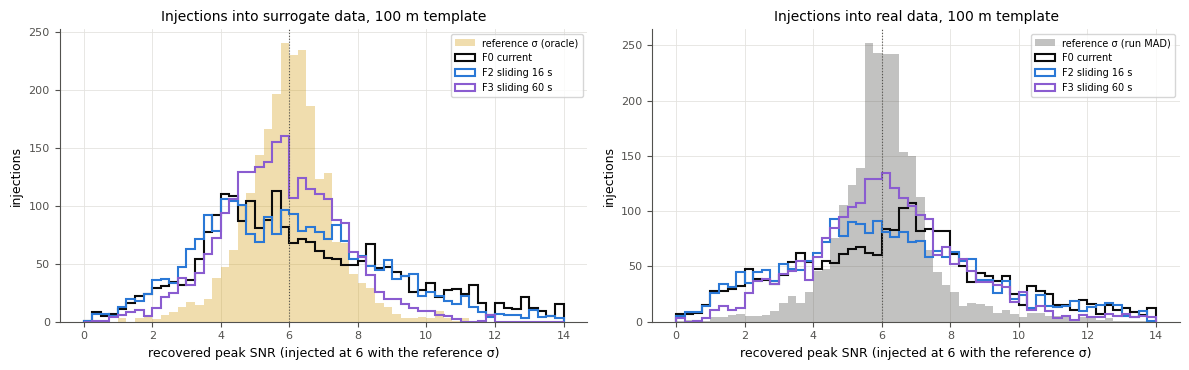

In [17]:
SUB = 20                                                       # sub-samples per 5.24 ms bin for the bin average

def sliding_at(a, dt, M, idx, window_s=None, step_s=0.05):
    """sigma_sliding evaluated at a single lag (same reflect padding and subsampling)."""
    w = window_samples(dt, M, window_s)
    step = max(1, int(round(step_s / dt)))
    sub = np.abs(a[::step])
    size = max(w // step, 3) | 1
    pad = np.pad(sub, size // 2, mode="symmetric")
    j = idx / step
    j0 = min(int(j), len(sub) - 1)
    j1 = min(j0 + 1, len(sub) - 1)
    m0, m1 = np.median(pad[j0:j0 + size]), np.median(pad[j1:j1 + size])
    return 1.4826 * (m0 + (j - j0) * (m1 - m0))

AT_LAG = {
    "F0 current": lambda a, dt, M, i: sigma_current(a, dt, M)[i],
    "F1 one block": lambda a, dt, M, i: sigma_one_block(a, dt, M)[i],
    "F2 sliding 16 s": lambda a, dt, M, i: sliding_at(a, dt, M, i),
    "F3 sliding 30 s": lambda a, dt, M, i: sliding_at(a, dt, M, i, 30.0),
    "F3 sliding 60 s": lambda a, dt, M, i: sliding_at(a, dt, M, i, 60.0),
    "F3 sliding 120 s": lambda a, dt, M, i: sliding_at(a, dt, M, i, 120.0),
    "F3 whole run": lambda a, dt, M, i: 1.4826 * np.median(np.abs(a)),
}
_a = STACK[FOCUS]["binned"]["a"]; _M = STACK[FOCUS]["binned"]["M"]; _dt = STACK[FOCUS]["binned"]["lc"].dt
for w_ in (None, 60.0):
    assert np.isclose(sliding_at(_a, _dt, _M, 12345, w_), sigma_sliding(_a, _dt, _M, w_)[12345], rtol=1e-6)

def event_response(lc, mf, key, t0, tt_, ti_):
    """(first lag, filter response a_s) of an additive unit-scale event at t0 on lc's grid."""
    T, M, n_lag = mf.template_delta, len(mf.template_delta), len(mf.time)
    j = int(np.searchsorted(lc.time, t0))
    lo, hi = max(j - M, 0), min(j + M, len(lc.time))
    offs = (np.arange(SUB) + 0.5) / SUB - 0.5
    tb = lc.time[lo:hi, None] + offs[None, :] * lc.dt
    s = RUNS[key]["sf"] * (np.interp(tb - t0, tt_, ti_, left=1.0, right=1.0) - 1.0).mean(axis=1)
    L0, L1 = max(lo - M + 1, 0), min(hi, n_lag)
    seg = np.zeros(L1 - L0 + M - 1)
    seg[lo - L0:hi - L0] = s
    return L0, np.correlate(seg, T, "valid") / mf.template_norm

def inject(key, kind, k, n, rng, target=6.0):
    rr = RUNS[key]
    lc = rr["binned"] if kind == "real" else surrogate(key, k)
    tt_, ti_ = rr["bank"][RADIUS]
    mf, a = filter_output(lc, tt_, ti_)
    M, dt = len(mf.template_delta), mf.dt_s
    s_ref = SIG_TRUE[(key, RADIUS)] if kind == "surrogate" else 1.4826 * np.median(np.abs(a))
    t0s = rng.uniform(lc.time[0] + 1.5 * DUR, lc.time[-1] - 1.5 * DUR, n)
    resp = [event_response(lc, mf, key, t0, tt_, ti_) for t0 in t0s]
    scale = target * s_ref / np.mean([r_[1].max() for r_ in resp])
    half = int(round(0.1 / dt))
    out = []
    for t0, (L0, a_s) in zip(t0s, resp):
        a_inj = a.copy()
        a_inj[L0:L0 + len(a_s)] += scale * a_s
        i_c = int(np.searchsorted(lc.time, t0)) - M // 2
        win = slice(max(i_c - half, 0), min(i_c + half + 1, len(a)))
        peak_a = a_inj[win].max()
        row = {"star": key[0], "channel": key[1], "kind": kind, "t0": t0, "ref": peak_a / s_ref}
        for est, fn in AT_LAG.items():
            row[est] = peak_a / fn(a_inj, dt, M, int(np.clip(i_c, 0, len(a) - 1)))
        out.append(row)
    return out

t_ = _time.time()
rng = np.random.default_rng(SEED + 7)
INJ = pd.DataFrame([row for key in RUNS for kind, k in (("real", -1), ("surrogate", 0))
                    for row in inject(key, kind, k, N_INJ, rng)])
print(f"{len(INJ)} injections in {_time.time() - t_:.0f} s")

rows = []
for kind in ("real", "surrogate"):
    sub = INJ[INJ.kind == kind]
    for est in ESTIMATORS:
        thr = THR.loc[est, f"single {kind} thr @{FAR_SINGLE:g}/h"]
        rows.append({"kind": kind, "estimator": est, "mean SNR": sub[est].mean(), "std SNR": sub[est].std(),
                     "std(SNR − ref)": (sub[est] - sub["ref"]).std(), "threshold": thr,
                     "efficiency": (sub[est] >= thr).mean(),
                     "efficiency @30/h": (sub[est] >= THR.loc[est, "single real thr @30/h"]).mean() if kind == "real" else np.nan})
    rows.append({"kind": kind, "estimator": "reference σ" + (" (oracle)" if kind == "surrogate" else " (run MAD)"),
                 "mean SNR": sub["ref"].mean(), "std SNR": sub["ref"].std(), "std(SNR − ref)": 0.0,
                 "threshold": THR.loc["oracle", f"single surrogate thr @{FAR_SINGLE:g}/h"] if kind == "surrogate" else np.nan,
                 "efficiency": (sub["ref"] >= THR.loc["oracle", f"single surrogate thr @{FAR_SINGLE:g}/h"]).mean()
                 if kind == "surrogate" else np.nan})
INJ_SUM = pd.DataFrame(rows)
display(INJ_SUM.round(3))


fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, kind in zip(axs, ("surrogate", "real")):
    style(ax)
    sub = INJ[INJ.kind == kind]
    bins = np.linspace(0, 14, 57)
    ax.hist(sub["ref"], bins=bins, color=EST_COLOR["oracle"] if kind == "surrogate" else MUTED, alpha=0.35,
            label="reference σ (oracle)" if kind == "surrogate" else "reference σ (run MAD)")
    for est in ("F0 current", "F2 sliding 16 s", "F3 sliding 60 s"):
        ax.hist(sub[est], bins=bins, histtype="step", lw=1.5, color=EST_COLOR[est], label=est)
    ax.axvline(6, color=MUTED, lw=0.8, ls=":")
    ax.set(xlabel="recovered peak SNR (injected at 6 with the reference σ)", ylabel="injections",
           title=f"Injections into {kind} data, 100 m template")
    ax.legend(fontsize=7)
finish(fig, "09_injection_snr")

**Reading the injections.**
* **Scatter.** On surrogates the oracle SNR scatters by ±1.3 (data noise only), while F0 scatters by ±3.0.
  The estimator adds more scatter than the data, in agreement with the ±40 % σ̂ error.
* **Bias.** F0's mean recovered SNR is ~7 % high, from the low bias of the median-of-block-MADs.
* **Efficiency at equal FAR, stationary noise.** Ranked: oracle (0.84) > whole run ≈ 120 s (0.71) > F2
  16 s (0.68) > 60 s > 30 s > F1 > F0 (0.49). The ranking is not monotonic in window length because F2's
  centred window also compresses the noise excursions it is tested on.
* **Efficiency at equal FAR, real data.** Short windows win (F2, F0, F3 30 s), and windows of 60 s or
  longer lose badly. The 10/h real threshold rests on the 5 loudest stretches of 0.5 telescope-hours,
  so the real-data efficiencies are uncertain at the ±10 % level.

## 5. Fixes

A good estimator must be **stable** (small scatter on stationary noise, no dependence on block edges)
and must **track** real changes in the noise level. The real runs vary by several × within minutes
(section 1: σ moves by ~3× along HD170263). Longer windows help the first and hurt the second. Two
tests probe the trade-off:

* **Block-edge sensitivity:** the section 3(c) shift test, applied to every estimator.
* **Tracking:** a surrogate of the focus run whose residual is multiplied by a known envelope e(t): a
  ×2 step half-way through, and a slow sinusoid 1 + 0.5 sin(2πt / 60 s). The true σ then becomes
  σ_true × e(t). The output is correlated over ~2 s and the envelope is much slower, so this holds at
  every lag except within ~1 s of the step.

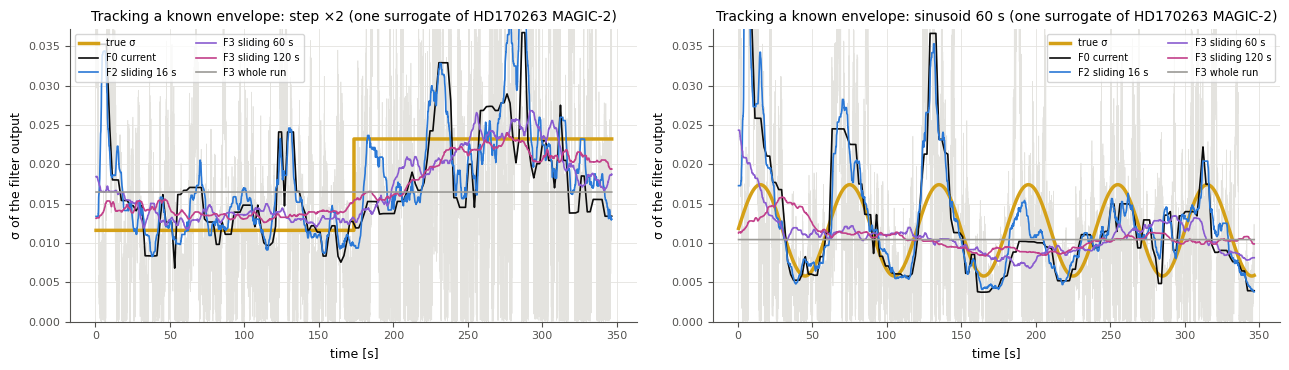

In [18]:
rows = []
for est, fn in ESTIMATORS.items():
    rr_ = []
    for key, st in STACK.items():
        b_ = st["binned"]
        k = int(round(1.0 / b_["lc"].dt))
        full = fn(b_["a"], b_["lc"].dt, b_["M"])
        rr_.append(fn(b_["a"][k:], b_["lc"].dt, b_["M"]) / full[k:])
    x = np.concatenate(rr_)
    rows.append({"estimator": est, "1 s shift p5": np.percentile(x, 5), "1 s shift p95": np.percentile(x, 95)})
SHIFT_ALL = pd.DataFrame(rows).set_index("estimator")

def track(env_fn, n_rep):
    key = FOCUS
    tt_, ti_ = RUNS[key]["bank"][RADIUS]
    res = {e: [] for e in ESTIMATORS}
    example = None
    for k in range(n_rep):
        sur = surrogate(key, 2000 + k)
        base, sg = compute_baseline_and_sigma(sur.time, sur.signal, DUR)
        tt0 = sur.time - sur.time[0]
        mod = LightCurve(sur.time, base * (1.0 + (sur.signal / base - 1.0) * env_fn(tt0)), meta=sur.meta)
        mf, a = filter_output(mod, tt_, ti_)
        truth = SIG_TRUE[(key, RADIUS)] * env_fn(mf.time - sur.time[0])
        edge = np.abs(mf.time - sur.time[0] - tt0[-1] / 2) > 1.0 if env_fn is ENV["step ×2"] else slice(None)
        for e, fn in ESTIMATORS.items():
            r_ = (fn(a, mf.dt_s, len(mf.template_delta)) / truth)[edge]
            res[e].append(np.log(r_))
        if k == 0:
            example = (mf.time - sur.time[0], a, truth, {e: fn(a, mf.dt_s, len(mf.template_delta)) for e, fn in ESTIMATORS.items()})
    return {e: np.concatenate(v) for e, v in res.items()}, example

half_run = (RUNS[FOCUS]["binned"].time[-1] - RUNS[FOCUS]["binned"].time[0]) / 2
ENV = {"stationary": lambda t: np.ones_like(t),
       "step ×2": lambda t: np.where(t < half_run, 1.0, 2.0),
       "sinusoid 60 s": lambda t: 1.0 + 0.5 * np.sin(2 * np.pi * t / 60.0)}
N_TRACK = 4 if QUICK else 12
TRACK, EXAMPLES = {}, {}
for name, fn in ENV.items():
    TRACK[name], EXAMPLES[name] = track(fn, N_TRACK)

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, name in zip(axs, ("step ×2", "sinusoid 60 s")):
    style(ax)
    t5, a, truth, amps_ = EXAMPLES[name]
    ax.plot(t5, np.abs(a), color=GRID, lw=0.5, zorder=0)
    ax.plot(t5, truth, color=EST_COLOR["oracle"], lw=2.5, label="true σ")
    for est in ("F0 current", "F2 sliding 16 s", "F3 sliding 60 s", "F3 sliding 120 s", "F3 whole run"):
        ax.plot(t5, amps_[est], color=EST_COLOR[est], lw=1.2, label=est)
    ax.set(xlabel="time [s]", ylabel="σ of the filter output", ylim=(0, 3.2 * SIG_TRUE[(FOCUS, RADIUS)]),
           title=f"Tracking a known envelope: {name} (one surrogate of {FOCUS[0]} {TEL[FOCUS[1]]})")
    ax.legend(fontsize=7, ncol=2)
finish(fig, "10_tracking")

### How non-stationary is the real noise?

Section 1 showed `amp_sigma` changing several-fold along a run. Section 4.2 shows that the estimator
alone produces a 0.5–2× spread on *stationary* noise. How much real variation is left? For every
channel-run, compare the spread of σ̂ along the run (p95/p5, sampled once per second) on the real data
with the same quantity on its stationary surrogates, for estimators of increasing window. If the real
spread clearly exceeds the surrogate spread, the noise level really changes on that time scale and the
window must be short enough to follow it.

estimator           F0 current  F2 sliding 16 s  F3 sliding 30 s  F3 sliding 60 s
star     telescope                                                               
HD170263 LST-1            1.90             2.04             2.02             1.58
         MAGIC-1          2.15             2.31             2.32             2.15
         MAGIC-2          1.07             1.11             1.38             1.45
HD176914 LST-1            0.66             0.95             0.79             0.98
         MAGIC-1          0.59             0.67             0.74             0.86
         MAGIC-2          1.01             1.02             1.33             1.20
HD196243 LST-1            2.37             2.63             1.46             1.87
         MAGIC-1          1.27             1.88             2.02             1.43
         MAGIC-2          0.63             0.92             0.67             0.88
HD199102 LST-1            3.10             2.31             1.95             2.30
         MAGIC-1          1.12             1.28             1.35             1.53
         MAGIC-2          1.50             2.07             1.66             1.56

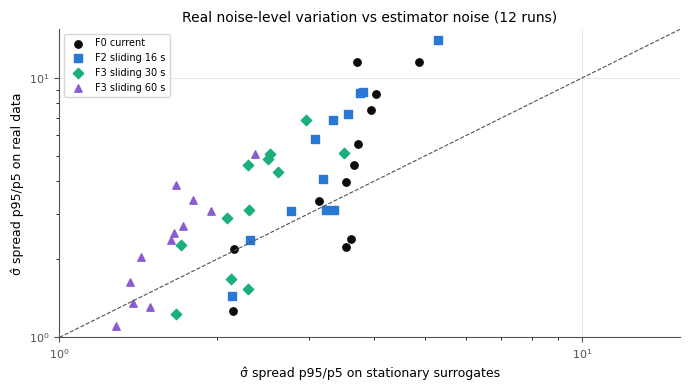

In [19]:
rows = []
for key, rr in RUNS.items():
    tt_, ti_ = rr["bank"][RADIUS]
    for est in ("F0 current", "F2 sliding 16 s", "F3 sliding 30 s", "F3 sliding 60 s"):
        def spread(lc):
            mf, a = filter_output(lc, tt_, ti_)
            s = ESTIMATORS[est](a, mf.dt_s, len(mf.template_delta))[::int(round(1.0 / mf.dt_s))]
            return np.percentile(s, 95) / np.percentile(s, 5)
        sur = [spread(surrogate(key, k)) for k in range(min(N_SURR, 8))]
        rows.append({"star": key[0], "telescope": TEL[key[1]], "estimator": est, "real p95/p5": spread(rr["binned"]),
                     "surrogate median": np.median(sur), "surrogate max": np.max(sur)})
NONSTAT = pd.DataFrame(rows)
NONSTAT["real / surrogate"] = NONSTAT["real p95/p5"] / NONSTAT["surrogate median"]
display(NONSTAT.pivot_table(index=["star", "telescope"], columns="estimator", values="real / surrogate").round(2))

fig, ax = plt.subplots(figsize=(7, 4)); style(ax)
for est, mk in zip(("F0 current", "F2 sliding 16 s", "F3 sliding 30 s", "F3 sliding 60 s"), "osD^"):
    d = NONSTAT[NONSTAT.estimator == est]
    ax.scatter(d["surrogate median"], d["real p95/p5"], color=EST_COLOR[est], marker=mk, s=28, label=est)
lim = [1, max(NONSTAT["real p95/p5"].max(), NONSTAT["surrogate max"].max()) * 1.1]
ax.plot(lim, lim, color=MUTED, lw=0.8, ls="--")
ax.set(xscale="log", yscale="log", xlim=lim, ylim=lim, xlabel="σ̂ spread p95/p5 on stationary surrogates",
       ylabel="σ̂ spread p95/p5 on real data", title="Real noise-level variation vs estimator noise (12 runs)")
ax.legend(fontsize=7)
finish(fig, "10b_nonstationarity")

With the 60 s window, 8 of the 12 channel-runs vary 1.4–2.3× more than their stationary surrogates
(largest: HD199102 LST-1, HD170263 MAGIC-1, HD196243 LST-1). Their noise level genuinely changes on
16–60 s scales. In the others (HD176914, HD196243 MAGIC-2) real and surrogate spreads are similar, so
the "variation" that the pipeline's σ̂ shows there is mostly estimator noise. This is why the real-data efficiency punishes long windows while the
surrogates reward them.

### Summary of the estimators

* **shift p5–p95:** σ ratio when the data start 1 s later (block-edge sensitivity), all 12 runs.
* **rms log err:** scatter of log(σ̂/σ_true) on the focus-run surrogate (stationary, step, sinusoid).
  0.10 ≈ 10 %.
* **SNR std/MAD, real:** calibration of the real-data SNR trace (median over runs; 1 is ideal).
* **thresholds:** SNR at the target FAR (single real/surrogate at `FAR_SINGLE`; 2-of-3 time slides and
  surrogates at `FAR_COINC`).
* **efficiency:** fraction of the SNR-6 injections above that estimator's own single-telescope
  threshold at `FAR_SINGLE`, and for real data also at 30/h. The real threshold at 10/h rests on the
  5 loudest of ~0.5 telescope-hours, so it is itself noisy; 30/h uses 15.

In [20]:
rows = []
for est in ESTIMATORS:
    row = {"estimator": est,
           "shift p5": SHIFT_ALL.loc[est, "1 s shift p5"], "shift p95": SHIFT_ALL.loc[est, "1 s shift p95"]}
    for name in ENV:
        row[f"rms log err, {name}"] = np.sqrt(np.mean(TRACK[name][est] ** 2))
    cr = CALIB[(CALIB.est == est) & (CALIB.kind == "real")]
    row["SNR std real"] = cr["snr_std"].median()
    row["SNR MAD real"] = cr["snr_mad"].median()
    for c in THR.columns:
        row[c] = THR.loc[est, c]
    for kind in ("real", "surrogate"):
        row[f"eff. {kind}"] = INJ_SUM[(INJ_SUM.kind == kind) & (INJ_SUM.estimator == est)]["efficiency"].iloc[0]
    row["eff. real @30/h"] = INJ_SUM[(INJ_SUM.kind == "real") & (INJ_SUM.estimator == est)]["efficiency @30/h"].iloc[0]
    rows.append(row)
SUMMARY = pd.DataFrame(rows).set_index("estimator")
display(SUMMARY.T.round(3))
SUMMARY.to_csv(OUT / "summary.csv")

estimator,F0 current,F1 one block,F2 sliding 16 s,F3 sliding 30 s,F3 sliding 60 s,F3 sliding 120 s,F3 whole run
shift p5,0.753,0.878,0.949,0.956,0.965,0.970,0.996
shift p95,1.408,1.173,1.052,1.043,1.046,1.044,1.019
"rms log err, stationary",0.354,0.204,0.309,0.236,0.176,0.124,0.041
"rms log err, step ×2",0.353,0.223,0.314,0.243,0.202,0.173,0.349
"rms log err, sinusoid 60 s",0.359,0.394,0.313,0.273,0.405,0.405,0.385
SNR std real,1.159,1.270,1.047,1.188,1.274,1.378,1.438
SNR MAD real,1.046,0.994,1.007,0.998,1.007,1.002,0.997
single real thr @10/h,7.548,8.177,6.273,6.968,7.728,8.230,8.680
single real thr @30/h,4.350,5.736,4.253,4.536,6.194,6.400,6.479
single surrogate thr @10/h,5.923,5.338,4.530,5.038,5.097,5.021,5.003


**Recommendation: replace the block estimator by a sliding (overlapping) window of ~16 s (F2).**

* **No block edges.** The 1 s shift test gives 0.95–1.05 instead of 0.75–1.41.
* **No bias.** Median σ̂/σ_true is 1.00 instead of 0.93.
* **Better-calibrated real SNR trace.** std 1.05 instead of 1.16.
* **Efficiency at equal FAR.** It beats F0 on surrogates (0.68 vs 0.49), and on real data it is equal
  at 30/h and better at 10/h (0.46 vs 0.35).
* **2-of-3 threshold.** Lower on the real time slides (3.5 vs 4.0 at 1/h).

It is cheap (a rolling median on the output subsampled at 50 ms).

It does not remove the underlying limit: on this red noise a 16 s window holds only ~5–10 independent
values, so σ̂ is still uncertain by ~30 %. Longer windows would be more precise but cannot follow the
real changes in noise level. Closing the remaining gap to the oracle (0.68 vs 0.84 on surrogates) needs
a σ that uses more information than the local |a|, for example a time-resolved noise PSD as in
`min_size` (`NoiseProfile.S_excess_blocks`), or a window that adapts to measured stationarity. The fix
was tested on one night only. Before adopting it, rerun the mimic FAR study and the min-size
calibration on all nights.

## 6. Appendix: sub-bin-shifted templates

The search slides the template in whole 5.24 ms steps, so an event whose centre falls inside a bin is
matched with a residual timing offset of up to half a bin. Against an *oracle* template (the event's
own bin-averaged pattern), white-noise tests lose ~1 % on average and up to ~4 % at the worst sub-bin
phase for the most compact star (0.01 mas) at 30 km/s, and ~0.1 % for 0.03 mas stars. A cheap remedy is
to search with *m* copies of each template, shifted by k·Δt/m (k = 0…m−1), and take the maximum SNR
over the copies at each lag.

* The copies are made by shifting the pattern on a fixed grid (`interp(tt − kΔt/m, tt, ti)`), so all of
  them have the same length and lags.
* All copies share the **same `amp_sigma`**, the pipeline estimate (F0) of the unshifted copy. A
  separate σ̂ per copy would put the estimator noise of section 4 into the maximum.
* m ∈ {1, 2, 5, 10}: the shifts of m = 2 and 5 are subsets of those of m = 10, so one set of FFTs
  serves all of them. m = 10 is the native-cadence limit.

In [21]:
MS = (1, 2, 5, 10)

def shifted(tt_, ti_, dt, m):
    return [(tt_, np.interp(tt_ - k * dt / m, tt_, ti_, left=1.0, right=1.0)) for k in range(m)]

def subbin_gain(tt_, ti_, dt, n, rng):
    """Peak response of m shifted copies to noiseless bin-averaged events at random sub-bin phases,
    as a fraction of the oracle (the event's own bin-averaged pattern as template), white noise."""
    grid = np.arange(tt_.min(), tt_.max(), dt)
    T = {k: np.interp(grid, *c) - 1.0 for k, c in enumerate(shifted(tt_, ti_, dt, 10))}
    j = np.arange(int(np.floor(tt_.min() / dt)) - len(grid), int(np.ceil(tt_.max() / dt)) + len(grid))
    offs = (np.arange(SUB) + 0.5) / SUB - 0.5
    out = {m: [] for m in MS}
    for ph in rng.uniform(0.0, 1.0, n):
        tb = (j[:, None] + offs[None, :]) * dt - ph * dt
        s = (np.interp(tb, tt_, ti_, left=1.0, right=1.0) - 1.0).mean(axis=1)
        oracle = np.sqrt(np.sum(s ** 2))
        peak = {k: (np.correlate(s, T[k], "valid") / np.linalg.norm(T[k])).max() for k in T}
        for m in MS:
            out[m].append(max(peak[k] for k in range(0, 10, 10 // m)) / oracle)
    return {m: np.array(v) for m, v in out.items()}

cfg1 = MimicConfig(template_radii_m=(100.0,))
inst_m2 = bank_instrument(TEL["A"], FILTER)
CASES = {f"{FOCUS[0]} per-star bank, 25 km/s": RUNS[FOCUS]["bank"][RADIUS]}
for v_ in (V, 30e3):
    (tt_, ti_), = search_templates(cfg1, v_, star_mas=0.01, instrument=inst_m2).values()
    CASES[f"0.01 mas, {v_/1e3:.0f} km/s"] = (tt_, ti_)
rng = np.random.default_rng(SEED + 11)
dt5 = RUNS[FOCUS]["binned"].dt
rows = []
for name, (tt_, ti_) in CASES.items():
    g = subbin_gain(tt_, ti_, dt5, 200 if QUICK else 600, rng)
    for m in MS:
        rows.append({"case": name, "m": m, "mean / oracle": g[m].mean(), "worst / oracle": g[m].min(),
                     "mean gain vs m=1": (g[m] / g[1]).mean(), "max gain vs m=1": (g[m] / g[1]).max()})
GAIN = pd.DataFrame(rows)
display(GAIN.round(4))

,case,m,mean / oracle,worst / oracle,mean gain vs m=1,max gain vs m=1
0,"HD170263 per-star bank, 25 km/s",1,0.9946,0.9836,1.0000,1.0000
1,"HD170263 per-star bank, 25 km/s",2,0.9986,0.9959,1.0040,1.0166
2,"HD170263 per-star bank, 25 km/s",5,0.9998,0.9993,1.0052,1.0160
3,"HD170263 per-star bank, 25 km/s",10,0.9999,0.9998,1.0053,1.0166
4,"0.01 mas, 25 km/s",1,0.9928,0.9789,1.0000,1.0000
5,"0.01 mas, 25 km/s",2,0.9982,0.9947,1.0055,1.0215
6,"0.01 mas, 25 km/s",5,0.9997,0.9991,1.0070,1.0206
7,"0.01 mas, 25 km/s",10,0.9999,0.9998,1.0072,1.0215
8,"0.01 mas, 30 km/s",1,0.9900,0.9700,1.0000,1.0000
9,"0.01 mas, 30 km/s",2,0.9974,0.9924,1.0075,1.0309


**The cost: false alarms.** The same surrogates and real runs are searched with m copies per template
(F0 normalisation shared). Copies shifted by a fraction of 5 ms are almost the same template and the
filter output is smooth on ~2 s, so the maximum over copies should barely move the noise tail.

appendix searches in 37 s


,single real thr @10/h,single real rate SNR≥5 [/h],single surrogate thr @10/h,single surrogate rate SNR≥5 [/h],2-of-3 timeslide thr @1/h,2-of-3 timeslide rate SNR≥5 [/h],2-of-3 surrogate thr @1/h,2-of-3 surrogate rate SNR≥5 [/h]
m,,,,,,,,
1,7.548,19.934,5.923,21.031,4.036,0.658,3.909,0.15
2,7.549,19.934,5.923,21.031,4.036,0.688,3.856,0.15
5,7.549,19.934,5.927,21.031,4.036,0.688,3.859,0.15
10,7.549,19.934,5.927,21.081,4.036,0.688,3.859,0.15


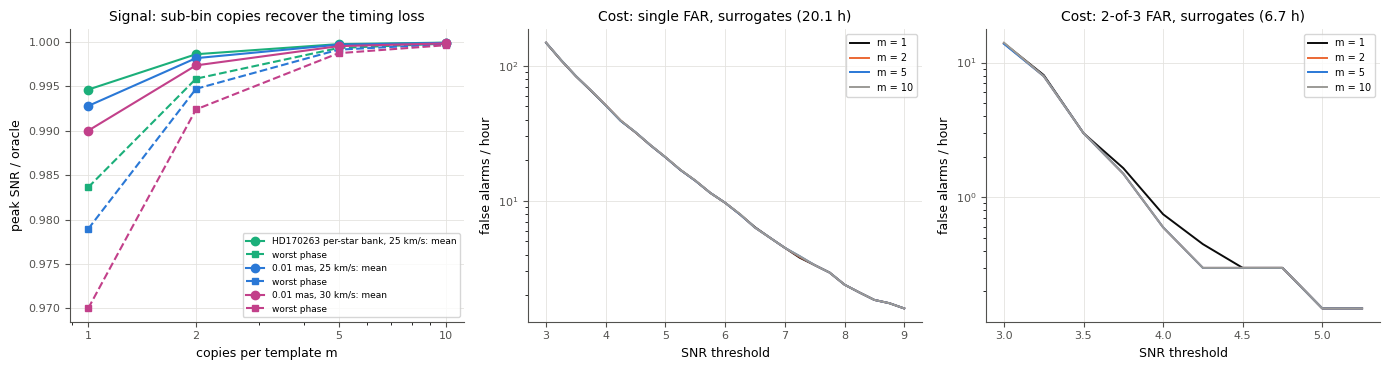

In [22]:
t_ = _time.time()
CAND_APP = []
for key, rr in RUNS.items():
    for kind, k in [("real", -1)] + [("surrogate", k) for k in range(N_SURR)]:
        lc = rr["binned"] if kind == "real" else surrogate(key, k)
        base, sg = compute_baseline_and_sigma(lc.time, lc.signal, DUR)
        copies = {R: [filter_output(lc, tc, ic, base, sg) for tc, ic in shifted(tt_, ti_, lc.dt, 10)]
                  for R, (tt_, ti_) in rr["bank"].items()}
        for m in MS:
            outs, amps = {}, {}
            for R, lst in copies.items():
                mf0, a0 = lst[0]
                amp0 = sigma_current(a0, mf0.dt_s, len(mf0.template_delta))
                a_max = np.max([lst[i][1] for i in range(0, 10, 10 // m)], axis=0)
                outs[R], amps[R] = (mf0, a_max), amp0
            for c in candidates(outs, amps):
                CAND_APP.append({"star": key[0], "channel": key[1], "kind": kind, "k": k, "est": f"m={m}", **c})
CAND_APP = pd.DataFrame(CAND_APP)
EV_APP = coincidences(CAND_APP, [("real", -1)] + [("surrogate", k) for k in range(N_SURR)], [f"m={m}" for m in MS])
print(f"appendix searches in {_time.time() - t_:.0f} s")

rows = []
for m in MS:
    fr = far_rows(CAND_APP, EV_APP, f"m={m}")
    row = {"m": m}
    for (scope, kind), (s, h) in fr.items():
        far = FAR_SINGLE if scope == "single" else FAR_COINC
        row[f"{scope} {kind} thr @{far:g}/h"] = threshold_for_far(s, h, far, SNR_FLOOR)
        row[f"{scope} {kind} rate SNR≥5 [/h]"] = (s >= 5).sum() / h
    rows.append(row)
FAR_APP = pd.DataFrame(rows).set_index("m")
assert np.allclose(FAR_APP.loc[1, f"single surrogate thr @{FAR_SINGLE:g}/h"],
                   THR.loc["F0 current", f"single surrogate thr @{FAR_SINGLE:g}/h"]), "m=1 must reproduce F0"
display(FAR_APP.round(3))

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
ax = style(axs[0])
for name, colr in zip(CASES, ("#1baf7a", "#2a78d6", "#c2408a")):
    g = GAIN[GAIN.case == name]
    ax.plot(g["m"], g["mean / oracle"], "o-", color=colr, label=f"{name}: mean")
    ax.plot(g["m"], g["worst / oracle"], "s--", color=colr, ms=4, label="worst phase")
ax.set(xscale="log", xticks=MS, xticklabels=[str(m) for m in MS], xlabel="copies per template m",
       ylabel="peak SNR / oracle", title="Signal: sub-bin copies recover the timing loss")
ax.legend(fontsize=6.5)
for ax, (scope, kind) in zip(axs[1:], (("single", "surrogate"), ("2-of-3", "surrogate"))):
    style(ax)
    for m, colr in zip(MS, ("#0b0b0b", "#eb6834", "#2a78d6", "#9b9a96")):
        s, h = far_rows(CAND_APP, EV_APP, f"m={m}")[(scope, kind)]
        rate = np.array([(s >= g_).sum() / h for g_ in SNR_GRID])
        ax.semilogy(SNR_GRID, np.where(rate > 0, rate, np.nan), color=colr, lw=1.4, label=f"m = {m}")
    ax.set(xlabel="SNR threshold", ylabel="false alarms / hour", title=f"Cost: {scope} FAR, {kind}s ({h:.1f} h)")
    ax.legend(fontsize=7)
finish(fig, "11_subbin_templates")

**Net effect** at fixed FAR: mean signal gain ÷ relative threshold increase. Values > 1 mean the copies
pay for themselves.

In [23]:
rows = []
for name in CASES:
    g = GAIN[GAIN.case == name].set_index("m")
    for m in MS[1:]:
        row = {"case": name, "m": m, "mean gain": g.loc[m, "mean gain vs m=1"]}
        for c in FAR_APP.columns:
            if "thr" in c:
                row[f"net, {c.replace(' thr', '')}"] = g.loc[m, "mean gain vs m=1"] / (FAR_APP.loc[m, c] / FAR_APP.loc[1, c])
        rows.append(row)
display(pd.DataFrame(rows).round(4))

,case,m,mean gain,"net, single real @10/h","net, single surrogate @10/h","net, 2-of-3 timeslide @1/h","net, 2-of-3 surrogate @1/h"
0,"HD170263 per-star bank, 25 km/s",2,1.0040,1.0040,1.0040,1.0040,1.0178
1,"HD170263 per-star bank, 25 km/s",5,1.0052,1.0051,1.0044,1.0052,1.0182
2,"HD170263 per-star bank, 25 km/s",10,1.0053,1.0053,1.0046,1.0053,1.0184
3,"0.01 mas, 25 km/s",2,1.0055,1.0055,1.0055,1.0055,1.0192
4,"0.01 mas, 25 km/s",5,1.0070,1.0070,1.0062,1.0070,1.0201
5,"0.01 mas, 25 km/s",10,1.0072,1.0072,1.0064,1.0072,1.0203
6,"0.01 mas, 30 km/s",2,1.0075,1.0075,1.0075,1.0075,1.0213
7,"0.01 mas, 30 km/s",5,1.0097,1.0097,1.0089,1.0097,1.0228
8,"0.01 mas, 30 km/s",10,1.0100,1.0100,1.0092,1.0100,1.0231


**Sub-bin copies.**
* **Gain.** With m = 2 the mean SNR gain is 0.4–0.75 % and the worst-phase gain 1.7–3 % (largest for the
  most compact star at 30 km/s). m = 5–10 adds another ~0.2 %.
* **Cost.** The single-telescope and 2-of-3 FAR curves are identical within the statistics: a sub-bin
  shift of a ~0.8 s template barely changes the noise output.
* **Net.** At fixed FAR it is a small (≲ 1 %) but free improvement for twice the correlation cost
  (which is the cheap part of the search). It matters only for the most compact stars and the fastest
  shadows, and it is far smaller than the effect of the noise estimator.

## Conclusions

Numbers from the full run (`QUICK = False`, 40 surrogates and 200 injections per channel-run), night
2026-08-19, 10 min of good time per telescope.

1. **Cadence is not the issue.** Native and 5.24 ms searches have the same baseline (to 0.1 %) and the
   same filter output (r ≥ 0.99). Their per-event SNR differences come from the noise estimate.
2. **The pipeline's noise estimate (F0) is noisy and biased.**
   * The filter output is correlated over τ ≈ 1.5–4 s, while the estimator's blocks are 2 s long, so it
     rests on ~5–10 independent values.
   * On stationary Gaussian surrogates σ̂/σ_true spans 0.51–2.01 (5–95 %, 42 % rms in log), with a median
     of 0.93.
   * Moving the block edges by 1 s alone changes it by 0.75–1.41.
3. **This costs detection efficiency.** On stationary noise at equal single-telescope FAR (10/h), F0
   detects 49 % of SNR-6 events against 84 % with the true σ. Its scatter is also visible as ±3 SNR
   units on injected events.
4. **Real noise is genuinely non-stationary in most runs** (8 of 12 show a σ spread 1.4–2.3× beyond
   estimator noise). Windows of 60 s or more, or one σ per run, are therefore much worse on real data even though
   they are best on stationary noise.
5. **Recommended fix:** a sliding (overlapping) ~16 s robust window (F2).
   * It removes the block-edge dependence and the bias.
   * It is at least as efficient as F0 everywhere (surrogates 0.68 vs 0.49; real 0.46 vs 0.35 at 10/h,
     equal at 30/h).
   * It lowers the 2-of-3 time-slide threshold.

   Reaching the oracle needs a better noise model than the local |a|, e.g. time-resolved PSDs.
6. **A second, separate source of FAR tails is the rolling-median baseline.** Even with the true σ, it
   makes the filter output of Gaussian noise non-Gaussian (excess kurtosis 0.95 for the pipeline's
   decimated median, 0.51 for the exact median, 0.01 for a running mean). Worth a dedicated study: a
   more linear baseline that still resists dips and glitches.
7. **Sub-bin-shifted templates (appendix):** +0.4–1 % mean SNR (up to 3 % at the worst phase), no
   measurable FAR cost.

None of this has changed the package. Adopting F2 means adding it as an `empirical_filter_sigma` mode and
rerunning the mimic FAR study and the min-size calibration.

In [24]:
print(f"notebook ran in {(_time.time() - T_START)/60:.1f} min (QUICK = {QUICK})")

notebook ran in 6.3 min (QUICK = False)
